# Introduction to Vision Transformers, made simple
**Gudsky Research Foundation · Research Intake 2026 · Day 38 (first day of the Vision Transformers & Vision-Language Models module)**

This is a hands-on notebook. Every idea from the Day 38 notes gets two things: **a plain-language explanation** (look for the 🧒 *In simple words* boxes) and **a small experiment you can run and see**. Whenever the notebook states a number, that number was printed by the code you are looking at.

> **The one big idea of the day:** a CNN looks at an image through a small sliding window and builds the big picture slowly, layer by layer. A **Vision Transformer (ViT)** chops the image into tiles ("patches"), turns every tile into a "word", and lets **every tile look at every other tile from the very first layer**. That freedom is powerful — but a ViT starts out knowing *nothing* about images, so it needs a lot of data (or a pretrained start).

## Roadmap
| Part | Topic (Day 38 section) | What you will do |
|---|---|---|
| 0 | Setup | load a real pretrained ViT-B/16, Fashion-MNIST, helpers |
| 1 | From CNNs to transformers (§1) | see *what a pixel can influence*: CNN window vs attention |
| 2 | The transformer recap (§2) | self-attention by hand, scaling factor, multi-head, the encoder block, quadratic cost |
| 3 | Patch embedding (§3) | an image becomes a sequence; patch embedding = one strided convolution; patch size vs cost |
| 4 | Position embeddings and [CLS] (§4) | prove attention ignores order; fixed vs learned positions; look inside a real ViT's positions |
| 5 | The ViT encoder and head (§5) | build a complete ViT from scratch; unit-test it; count parameters; trace a forward pass |
| 6 | ViT vs CNN: inductive bias (§6) | measure the data-hunger of a from-scratch ViT against a CNN |
| 7 | Training ViT (§7) | augmentation, regularisation, warmup, distillation (DeiT-style), precision |
| 8 | ViT in practice (§8) | pretrained ViT-B/16, preprocessing pitfalls, position-embedding interpolation, attention maps, fine-tuning vs linear probing, gradient accumulation |
| 9 | Applications (§9) | where ViT is used; token counting for video; ethics |
| 10 | Frontiers and choosing CNN vs ViT (§10) | windowed attention cost; decision table |
| 11 | Debugging checklist as code, glossary, quiz, PP16 map, references (§11) | automated checks that catch classic ViT bugs |

## How to read the boxes
* 🧒 **In simple words** — the idea with an everyday comparison.
* 🔧 **How it works** — the steps, short.
* ⚠️ **Watch out** — the usual mistake.

## Honest labels used throughout
* `[measured]` — a number printed by this notebook's code.
* `[computed]` — plain arithmetic or a formula evaluated by code.
* `[assumed]` — a value we had to choose.
* `[from the notes]` / `[established]` — a claim from the Day 38 PDF or the literature that this notebook does not re-test.

## Scope, stated up front
* Everything runs on a plain **CPU**, so all *trained-from-scratch* models are deliberately **small** and the datasets are **Fashion-MNIST (28×28 grey)**, not ImageNet/CIFAR. What the notebook shows is how the *mechanisms* behave; it does **not** reproduce published accuracy numbers.
* The one **large** model used is the real pretrained **ViT-B/16** (used for inference, attention maps, feature extraction and a short fine-tune).
* The graded assignment **PP16** (a from-scratch ViT *and* a fine-tuned ViT with a written comparison) is **not** solved here; Part 11 maps each idea onto the PP16 requirements.
* Total run time is printed at the end.

In [3]:
from __future__ import annotations

import gzip
import math
import os
import ssl
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from skimage import data as skdata

warnings.filterwarnings("ignore", category=UserWarning)
NB_START = time.time()
SEED = 38
QUICK = os.environ.get("VIT_QUICK", "0") == "1"  # smoke-test mode: tiny budgets, same code
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, os.cpu_count() or 1))
DATA_DIR = Path("vit_data")
DATA_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False, "image.cmap": "gray"})


def seed_all(seed: int = SEED) -> None:
    torch.manual_seed(seed)
    np.random.seed(seed)


def table(rows: list[list], header: list[str]) -> None:
    """Plain-text table (works anywhere, no extra packages)."""
    w = [max(len(str(r[i])) for r in [header] + rows) for i in range(len(header))]
    line = lambda r: "  ".join(str(c).ljust(w[i]) for i, c in enumerate(r))  # noqa: E731
    print(line(header))
    print("  ".join("-" * x for x in w))
    for r in rows:
        print(line(r))


def download(url: str, dest: Path, timeout: int = 300) -> bool:
    """Download once, cache in vit_data/. Returns False (and says so) instead of crashing when a host is unreachable."""
    if dest.exists() and dest.stat().st_size > 0:
        return True
    try:
        try:
            resp = urllib.request.urlopen(url, timeout=timeout)
        except ssl.SSLError:
            import certifi

            resp = urllib.request.urlopen(url, timeout=timeout, context=ssl.create_default_context(cafile=certifi.where()))
        with resp, open(dest, "wb") as fh:
            fh.write(resp.read())
        return True
    except Exception as exc:  # noqa: BLE001 - report any network problem plainly
        print(f"  could not download {url.split('/')[-1]}: {type(exc).__name__}")
        dest.unlink(missing_ok=True)
        return False


def show_row(images: list[np.ndarray], titles: list[str] | None = None, size: float = 2.4, cmap: str | None = None, vmin=None, vmax=None) -> None:
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.4))
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.axis("off")
        if titles:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    plt.show()


def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())


seed_all()
print(f"torch {torch.__version__} | device {DEVICE} | threads {torch.get_num_threads()} | QUICK={QUICK}")

torch 2.14.1+cu130 | device cuda | threads 2 | QUICK=False


## Part 0 — Data and models you will use
1. **Fashion-MNIST** (Xiao et al., 2017): 70 000 small grey pictures of clothes in 10 classes. We use it because it is small enough for a CPU, yet not trivial. Downloaded from the dataset's GitHub repository.
2. **A real pretrained ViT-B/16**: the original ViT-Base checkpoint (patch 16, 224×224 input) as packaged by the `timm` library, downloaded from its GitHub release. It is the model the notes' §8.1 calls `vit-base-patch16-224`.
3. **A few ordinary photographs** bundled with scikit-image, for attention maps.

Fashion-MNIST: train (60000, 1, 28, 28), test (10000, 1, 28, 28), classes ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']


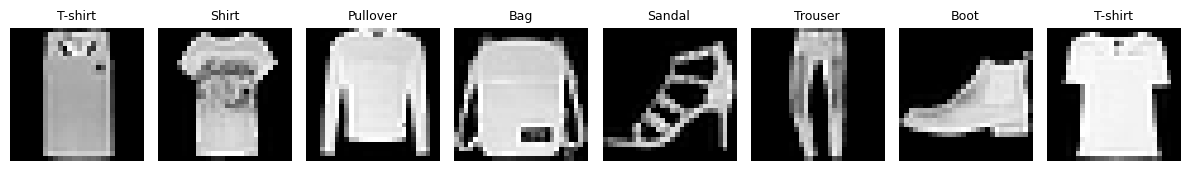

pretrained ViT-B/16: ready


In [4]:
FM_BASE = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
VITB_URL = "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-vitjx/jx_vit_base_p16_224-80ecf9dd.pth"
FM_CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

HAVE_FM = all(download(FM_BASE + f + ".gz", DATA_DIR / (f + ".gz")) for f in ["train-images-idx3-ubyte", "train-labels-idx1-ubyte", "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"])
HAVE_VITB = download(VITB_URL, DATA_DIR / "jx_vit_base_p16_224.pth", timeout=900)


def _idx(path: Path) -> np.ndarray:
    with gzip.open(path, "rb") as fh:
        raw = fh.read()
    nd = raw[3]
    shape = tuple(int.from_bytes(raw[4 + 4 * i: 8 + 4 * i], "big") for i in range(nd))
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(shape)


if HAVE_FM:
    _rng = np.random.default_rng(SEED)
    _xtr, _ytr = _idx(DATA_DIR / "train-images-idx3-ubyte.gz"), _idx(DATA_DIR / "train-labels-idx1-ubyte.gz")
    _xte, _yte = _idx(DATA_DIR / "t10k-images-idx3-ubyte.gz"), _idx(DATA_DIR / "t10k-labels-idx1-ubyte.gz")
    _perm = _rng.permutation(len(_xtr))  # fixed shuffle so "the first n images" is a fair random subset
    XTR = torch.from_numpy(_xtr[_perm]).float().div(255).unsqueeze(1)
    YTR = torch.from_numpy(_ytr[_perm]).long()
    XTE = torch.from_numpy(_xte).float().div(255).unsqueeze(1)
    YTE = torch.from_numpy(_yte).long()
    print(f"Fashion-MNIST: train {tuple(XTR.shape)}, test {tuple(XTE.shape)}, classes {FM_CLASSES}")
    show_row([XTR[i, 0].numpy() for i in range(8)], [FM_CLASSES[int(YTR[i])] for i in range(8)], size=1.5)
else:
    print("Fashion-MNIST not available offline -> Parts 6, 7, 8 (fine-tuning) will be skipped")

print("pretrained ViT-B/16:", "ready" if HAVE_VITB else "NOT available (Part 8 will say what it skips)")


def make_vit_b(img_size: int = 224, num_classes: int = 1000, pretrained: bool = True) -> nn.Module:
    """timm ViT-B/16. With pretrained=True the original weights are loaded; when img_size != 224 timm resamples the
    position embeddings onto the new patch grid (the 'interpolation' of Day 38 section 8.3)."""
    import timm
    from timm.models.vision_transformer import checkpoint_filter_fn

    m = timm.create_model("vit_base_patch16_224", pretrained=False, img_size=img_size)
    if pretrained:
        sd = torch.load(DATA_DIR / "jx_vit_base_p16_224.pth", map_location="cpu", weights_only=True)
        m.load_state_dict(checkpoint_filter_fn(sd, m), strict=True)
    if num_classes != 1000:
        m.reset_classifier(num_classes)
    return m


from torchvision.models import ResNet18_Weights  # noqa: E402  (bundled class names only, no download)

IMAGENET_CLASSES = ResNet18_Weights.IMAGENET1K_V1.meta["categories"]

# Part 1 — From CNNs to Transformers: closing the loop (§1)
### 🧒 In simple words
Imagine reading a page of text.
* A **CNN** reads through a small *magnifying glass*: it sees a few letters at a time and only gradually (stacking many layers) understands the whole page.
* A **transformer** reads *the whole page at once* and, for every word, asks *"which other words matter for understanding me?"* — that question is **attention**.

A Vision Transformer applies the transformer to a picture by cutting it into square tiles and treating every tile like a word.

**Three words that are easy to mix up (§1.6):** *transformer* = the whole architecture family; *attention* = its core "who looks at whom" mechanism; *ViT* = a transformer applied to images via patches. Every ViT uses attention; not every use of attention is a ViT.

### 1.1 See the difference: what can one output unit be influenced by?
We measure it directly. For a **CNN** (four stacked 3×3 convolutions) we ask: *"which input pixels can change the output at the centre?"* For **one self-attention layer** over an 8×8 grid of tiles we ask the same thing. A pixel/tile that can influence the output has a **non-zero gradient**; the others have exactly zero. `[measured]`

[measured] CNN, 4 layers of 3x3: centre output depends on 81 of 256 pixels (a 9x9 window; formula 1+4*(3-1) = 9)
[measured] ONE attention layer: the output of one tile depends on 64 of 64 tiles (everything)


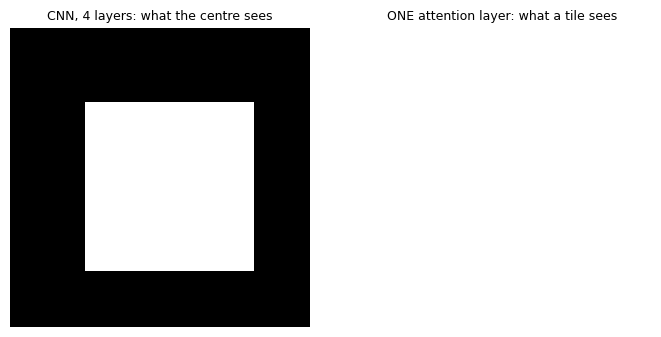

In [5]:
seed_all()
# CNN: 4 stacked 3x3 convs with all weights equal and no non-linearity, so the gradient map is exactly the receptive field
cnn = nn.Sequential(*[nn.Conv2d(1, 1, 3, padding=1, bias=False) for _ in range(4)])
for c in cnn:
    nn.init.constant_(c.weight, 0.1)
img = torch.zeros(1, 1, 16, 16, requires_grad=True)
cnn(img)[0, 0, 8, 8].backward()
rf_cnn = (img.grad[0, 0] != 0).float()

# one multi-head self-attention layer over an 8x8 grid of tiles (each tile = a 16-dim vector)
attn = nn.MultiheadAttention(16, 2, batch_first=True)
tok = torch.randn(1, 64, 16, requires_grad=True)
out, _ = attn(tok, tok, tok)
out[0, 4 * 8 + 4].sum().backward()
rf_attn = (tok.grad[0].abs().sum(-1) > 0).float().reshape(8, 8)

print(f"[measured] CNN, 4 layers of 3x3: centre output depends on {int(rf_cnn.sum())} of {rf_cnn.numel()} pixels (a {int(rf_cnn.sum() ** 0.5)}x{int(rf_cnn.sum() ** 0.5)} window; formula 1+4*(3-1) = {1 + 4 * 2})")
print(f"[measured] ONE attention layer: the output of one tile depends on {int(rf_attn.sum())} of {rf_attn.numel()} tiles (everything)")
fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
ax[0].imshow(rf_cnn, vmin=0, vmax=1)
ax[0].set_title("CNN, 4 layers: what the centre sees", fontsize=9)
ax[1].imshow(rf_attn, vmin=0, vmax=1)
ax[1].set_title("ONE attention layer: what a tile sees", fontsize=9)
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Reading the figure.** The CNN needs *depth* to widen its window (each extra 3×3 layer widens the window by 1 pixel on every side). A single attention layer already connects every tile with every other — no depth required. That is the "closing the loop" of §1: the same task (look at an image) solved with a completely different assumption. The price (Part 6): the CNN's small window is *prior knowledge* that happens to be true for images; the transformer has to *learn* that nearby tiles matter.

### 1.2 Why did vision follow language? (§1.2–1.3, `[from the notes]`)
* 2017: the transformer was invented for **machine translation** — relating words however far apart they are ("…it was too big" → *what* is "it"?). It trained faster in parallel than the recurrent networks used before.
* 2020: the Vision Transformer paper (Dosovitskiy et al.) showed that if an image becomes a **sequence of tokens**, the unchanged transformer encoder can classify it. Almost all the novelty is in the *input representation* (Part 3).
* Then five days of this module: Day 38 foundations → 39 efficient/hierarchical variants → 40 language → 41 CLIP → 42 modern vision-language models.

# Part 2 — The transformer recap: self-attention, multi-head, the encoder block (§2)
### 🧒 In simple words
**Tokens.** A transformer reads a *list* of vectors called tokens (for text: words; for a ViT: image tiles). A list of N tokens, each a vector of length *d*, is just an **N × d table**. The transformer keeps that table's shape the whole way through (§2.1).

**Self-attention** answers: *"for each token, how much should it listen to each of the others?"* Every token is turned into three vectors:
* a **query** *q* — "what am I looking for?"
* a **key** *k* — "what do I contain?"
* a **value** *v* — "what do I hand over if someone listens to me?"

Token *i* compares its query with every key (dot product = how well they match), turns the match-scores into percentages that add up to 100 % (**softmax**), and takes that percentage-weighted mix of all the values. That mix is token *i*'s new vector.

🔧 **Three steps** (§2.2): **score** = q·kᵀ / √d_k → **softmax** each row → **weighted sum** of values.

### 2.1 Attention by hand on 6 tokens (§2.2.1)
Same size as the notes' worked example: 6 tokens, key size d_k = 4. The numbers are random (seeded), so they will differ from the notes' picture, but the *behaviour* is the same. We compute the three steps ourselves and check them against PyTorch's built-in. `[measured]`

rows of the weight matrix sum to: [1. 1. 1. 1. 1. 1.]
[measured] max |by-hand - PyTorch built-in| = 5.96e-08


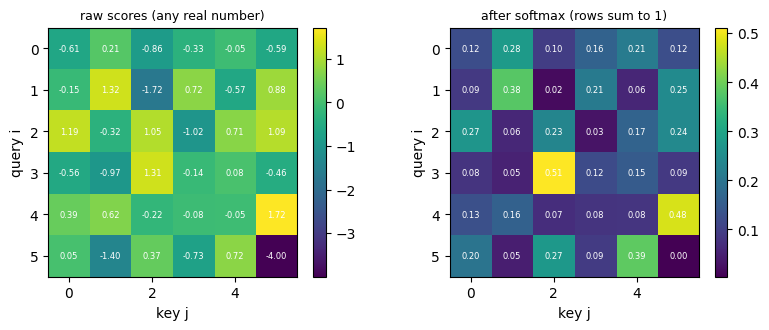

sharpest row: 3 (max weight 0.51) | most spread-out row: 2 (max weight 0.27)


In [6]:
seed_all()
N6, DK = 6, 4
Q, K, V = torch.randn(N6, DK), torch.randn(N6, DK), torch.randn(N6, DK)
raw = Q @ K.T / math.sqrt(DK)  # step 1: scaled scores, one per (query, key) pair
w = raw.softmax(dim=-1)  # step 2: each row becomes a probability distribution
out_hand = w @ V  # step 3: weighted blend of the value vectors
out_ref = F.scaled_dot_product_attention(Q[None], K[None], V[None])[0]
print("rows of the weight matrix sum to:", w.sum(-1).numpy().round(4))
print(f"[measured] max |by-hand - PyTorch built-in| = {float((out_hand - out_ref).abs().max()):.2e}")
fig, ax = plt.subplots(1, 2, figsize=(8.2, 3.4))
for a, M, ttl in [(ax[0], raw, "raw scores (any real number)"), (ax[1], w, "after softmax (rows sum to 1)")]:
    im = a.imshow(M.numpy(), cmap="viridis")
    a.set_title(ttl, fontsize=9)
    a.set_xlabel("key j")
    a.set_ylabel("query i")
    plt.colorbar(im, ax=a, fraction=0.046)
    for i in range(N6):
        for j in range(N6):
            a.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="w", fontsize=6)
plt.tight_layout()
plt.show()
print("sharpest row:", int(w.max(-1).values.argmax()), "(max weight %.2f)" % float(w.max()), "| most spread-out row:", int(w.max(-1).values.argmin()), "(max weight %.2f)" % float(w.max(-1).values.min()))

**Reading the figure.** Some rows are *confident* (one key gets most of the weight), others *spread out* across several keys. That flexible, **content-dependent** weighting is what a CNN kernel cannot do: a kernel's weights are fixed after training and identical for every image, while attention weights are **recomputed for every input**.

### 2.2 Why divide by √d_k? (§2.4)
🧒 If you add up more numbers, the total gets bigger. A dot product of two length-*d* vectors adds up *d* products, so with larger *d* the raw scores get larger, and softmax of large numbers turns into "100 % on one key, 0 % on the rest" — where its **gradient is almost zero**, so learning stalls. Dividing by √d keeps the scores at a steady size. We test it. `[measured]`

In [7]:
seed_all()
rows = []
for d in [4, 16, 64, 256, 1024]:
    q, k = torch.randn(2000, 8, d), torch.randn(2000, 8, d)  # 2000 random queries, each against 8 keys
    s_raw = torch.einsum("bd,bkd->bk", q[:, 0], k)  # unscaled scores
    s_sc = s_raw / math.sqrt(d)
    res = []
    for s in (s_raw, s_sc):
        s = s.clone().requires_grad_(True)
        p = s.softmax(-1)
        # gradient of the largest weight with respect to the scores: how much can learning move the attention?
        p.max(-1).values.sum().backward()
        res.append((float(p.max(-1).values.mean()), float(s.grad.abs().mean())))
    rows.append([d, f"{float(s_raw.std()):.1f}", f"{float(s_sc.std()):.2f}", f"{res[0][0]:.2f}", f"{res[1][0]:.2f}", f"{res[0][1]:.4f}", f"{res[1][1]:.4f}"])
table(rows, ["d_k", "std of raw scores", "std after /sqrt(d)", "top weight, unscaled", "top weight, scaled", "mean |gradient|, unscaled", "mean |gradient|, scaled"])

d_k   std of raw scores  std after /sqrt(d)  top weight, unscaled  top weight, scaled  mean |gradient|, unscaled  mean |gradient|, scaled
----  -----------------  ------------------  --------------------  ------------------  -------------------------  -----------------------
4     2.0                1.00                0.53                  0.35                0.0513                     0.0517                 
16    4.0                1.00                0.75                  0.36                0.0365                     0.0537                 
64    8.0                1.00                0.87                  0.36                0.0215                     0.0539                 
256   16.1               1.01                0.93                  0.36                0.0113                     0.0542                 
1024  32.2               1.01                0.97                  0.36                0.0058                     0.0542                 


**Reading the table.** Without scaling the score spread grows like √d_k, the top attention weight drifts towards 1.0 (a nearly one-hot choice) and the mean gradient shrinks; with scaling the spread stays near 1 and the gradient stays healthy. It is a one-line detail with no error message when forgotten — we will test for it in Part 11.

### 2.3 Multi-head attention (§2.3) — written from scratch
🧒 One attention pattern is one *opinion* about which tokens matter. **Several heads** run in parallel, each with its own q/k/v projections, so the model can hold several opinions at once (one head may watch close neighbours, another a distant but related tile). Their outputs are glued together and mixed by one more linear layer.

Below is our own implementation (it will be reused for the whole ViT). We verify it against PyTorch's `nn.MultiheadAttention` by copying the same weights into both. `[measured]`

In [8]:
class MHSA(nn.Module):
    """Multi-head self-attention, written out explicitly. `scale=False` is a deliberate bug switch used only in Part 11."""

    def __init__(self, d: int, heads: int, scale: bool = True, attn_drop: float = 0.0) -> None:
        super().__init__()
        assert d % heads == 0, "embedding size must be divisible by the number of heads"
        self.h, self.dk, self.scale_on = heads, d // heads, scale
        self.qkv = nn.Linear(d, 3 * d)  # one matrix that produces q, k and v for every head
        self.proj = nn.Linear(d, d)  # final mixing of the concatenated heads
        self.drop = nn.Dropout(attn_drop)
        self.last_attn: torch.Tensor | None = None

    def forward(self, x: torch.Tensor, mask: torch.Tensor | None = None) -> torch.Tensor:
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, self.dk).permute(2, 0, 3, 1, 4)  # each (B, heads, N, dk)
        scores = q @ k.transpose(-2, -1)
        if self.scale_on:
            scores = scores / math.sqrt(self.dk)
        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))
        attn = scores.softmax(-1)  # (B, heads, N, N)
        self.last_attn = attn.detach()
        out = (self.drop(attn) @ v).transpose(1, 2).reshape(B, N, D)
        return self.proj(out)


seed_all()
mine = MHSA(32, 4)
ref = nn.MultiheadAttention(32, 4, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(mine.qkv.weight)
    ref.in_proj_bias.copy_(mine.qkv.bias)
    ref.out_proj.weight.copy_(mine.proj.weight)
    ref.out_proj.bias.copy_(mine.proj.bias)
xt = torch.randn(3, 10, 32)
print(f"[measured] our MHSA vs nn.MultiheadAttention, same weights: max difference = {float((mine(xt) - ref(xt, xt, xt)[0]).abs().max()):.2e}; output shape {tuple(mine(xt).shape)} (same as input {tuple(xt.shape)})")
print(f"attention tensor: {tuple(mine.last_attn.shape)} = (batch, heads, tokens, tokens)")

[measured] our MHSA vs nn.MultiheadAttention, same weights: max difference = 8.94e-08; output shape (3, 10, 32) (same as input (3, 10, 32))
attention tensor: (3, 4, 10, 10) = (batch, heads, tokens, tokens)


### 2.4 The encoder block: LayerNorm, residual connections, feed-forward (§2.5)
🔧 One block = two sub-steps, each wrapped as **"normalise → transform → add the input back"**:
1. `x = x + Attention(LayerNorm(x))` — tokens exchange information.
2. `x = x + MLP(LayerNorm(x))` — each token is processed on its own by a small network (hidden size 4× wider).

* **Residual ("add the input back")** gives gradients a clean highway back through many blocks — the same fix as ResNet (Day 30).
* **LayerNorm** normalises *one token's own features* (unlike BatchNorm, which normalises across a batch of images).
* **Pre-norm** (normalise *before* each sub-layer, as here) trains more stably than the original paper's **post-norm**, so it is today's default.

⚠️ Shape is preserved: N × d in, N × d out. That is why you can stack as many blocks as you like.

In [9]:
class DropPath(nn.Module):
    """Stochastic depth (§7.3): during training, randomly skip a block's contribution for some images."""

    def __init__(self, p: float = 0.0) -> None:
        super().__init__()
        self.p = p

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.p == 0.0:
            return x
        keep = 1 - self.p
        mask = (torch.rand(x.shape[0], 1, 1, device=x.device) < keep).to(x.dtype)
        return x * mask / keep


class Block(nn.Module):
    """Pre-norm transformer encoder block. `residual=False` is a deliberate bug switch used only in Part 11."""

    def __init__(self, d: int, heads: int, mlp_ratio: int = 4, drop: float = 0.0, drop_path: float = 0.0, scale: bool = True, residual: bool = True) -> None:
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = MHSA(d, heads, scale=scale)
        self.mlp = nn.Sequential(nn.Linear(d, mlp_ratio * d), nn.GELU(), nn.Dropout(drop), nn.Linear(mlp_ratio * d, d), nn.Dropout(drop))
        self.dp = DropPath(drop_path)
        self.residual = residual

    def forward(self, x: torch.Tensor, mask: torch.Tensor | None = None) -> torch.Tensor:
        a = self.dp(self.attn(self.n1(x), mask))
        x = x + a if self.residual else a
        m = self.dp(self.mlp(self.n2(x)))
        return x + m if self.residual else m


blk = Block(64, 4)
xt = torch.randn(2, 50, 64)
print(f"[measured] block input {tuple(xt.shape)} -> output {tuple(blk(xt).shape)}  (shape preserved)")
ln_out = nn.LayerNorm(64, elementwise_affine=False)(xt)
print(f"LayerNorm normalises each TOKEN: mean of token 0 = {float(ln_out[0, 0].mean()):.1e}, std = {float(ln_out[0, 0].std(unbiased=False)):.3f}")

[measured] block input (2, 50, 64) -> output (2, 50, 64)  (shape preserved)
LayerNorm normalises each TOKEN: mean of token 0 = -9.3e-09, std = 1.000


### 2.5 Encoder vs decoder, and bidirectional vs causal attention (§2.6, §2.8)
* The original transformer had an **encoder** (reads the whole input) and a **decoder** (writes an output one word at a time). A ViT only needs to *read* an image and output one label, so it uses **only the encoder**. (The word "encoder-decoder" also appears in segmentation networks like U-Net, with a different meaning: shrink-then-expand a feature map. Same words, unrelated mechanisms.)
* **Bidirectional** attention: every token may look at every token (a ViT: there is no "earlier" tile). **Causal** attention: a token may only look at itself and *earlier* tokens (a text generator must not peek at words it has not written yet). Day 40 will combine both in vision-language models. We can *see* the difference as a mask on the same attention weights: `[measured]`

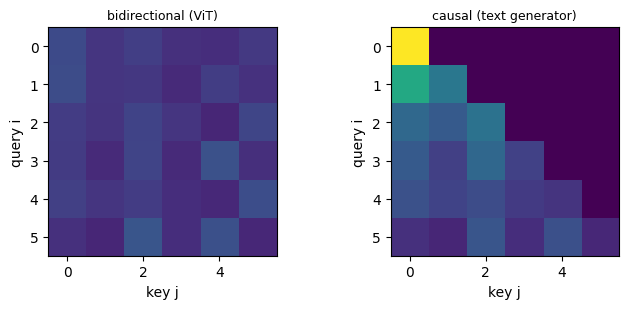

causal: weight on future tokens = 0.0 (exactly zero); bidirectional: 2.47 in total


In [10]:
seed_all()
mha = MHSA(16, 2)
x6 = torch.randn(1, 6, 16)
causal = torch.tril(torch.ones(6, 6, dtype=torch.bool))
mha(x6)
bidir = mha.last_attn[0, 0].clone()
mha(x6, mask=causal)
caus = mha.last_attn[0, 0].clone()
fig, ax = plt.subplots(1, 2, figsize=(7, 3.2))
for a, M, t in [(ax[0], bidir, "bidirectional (ViT)"), (ax[1], caus, "causal (text generator)")]:
    a.imshow(M.numpy(), cmap="viridis", vmin=0, vmax=1)
    a.set_title(t, fontsize=9)
    a.set_xlabel("key j")
    a.set_ylabel("query i")
plt.tight_layout()
plt.show()
print(f"causal: weight on future tokens = {float(caus.triu(1).sum()):.1f} (exactly zero); bidirectional: {float(bidir.triu(1).sum()):.2f} in total")

### 2.6 The price of "everyone looks at everyone": quadratic cost (§2.7)
Scores for **N** tokens means **N × N** pairs, so attention costs about **N² × d** operations — *quadratic* in N. A convolution does a fixed amount of work per position, so its cost is *linear* in the number of positions. This single fact drives the rest of the module (Day 39).

We count the floating-point operations of the attention core (the two big matrix products `QKᵀ` and `weights·V`) with PyTorch's counter and time it, for the token counts that appear later (49, 196, 784, 3136). `[measured]`

In [11]:
from torch.utils.flop_counter import FlopCounterMode


def attention_core(n: int, heads: int = 12, head_dim: int = 64) -> tuple[int, float]:
    q = torch.randn(1, heads, n, head_dim)
    k, v = torch.randn_like(q), torch.randn_like(q)
    with FlopCounterMode(display=False) as fc:
        t = time.time()
        (((q @ k.transpose(-2, -1)) / 8).softmax(-1) @ v).sum().item()
        dt = time.time() - t
    return fc.get_total_flops(), dt


def conv_cost(n_positions: int) -> int:
    side = int(n_positions ** 0.5)
    conv = nn.Conv2d(64, 64, 3, padding=1)
    with FlopCounterMode(display=False) as fc:
        conv(torch.zeros(1, 64, side, side))
    return fc.get_total_flops()


base_f, base_t = attention_core(49)
base_c = conv_cost(49)
rows = []
for n in [49, 196, 784, 3136]:
    f, t = attention_core(n)
    rows.append([n, n * n, f"{f / 1e6:.0f} MFLOPs", f"{f / base_f:.0f}x", f"{(n / 49) ** 2:.0f}x", f"{conv_cost(n) / base_c:.0f}x", f"{t * 1000:.0f} ms"])
table(rows, ["tokens N", "pairs N^2", "attention FLOPs (12 heads)", "attention vs N=49", "N^2 prediction", "3x3 conv vs N=49 positions", "time here"])

tokens N  pairs N^2  attention FLOPs (12 heads)  attention vs N=49  N^2 prediction  3x3 conv vs N=49 positions  time here
--------  ---------  --------------------------  -----------------  --------------  --------------------------  ---------
49        2401       7 MFLOPs                    1x                 1x              1x                          2 ms     
196       38416      118 MFLOPs                  16x                16x             4x                          4 ms     
784       614656     1888 MFLOPs                 256x               256x            16x                         53 ms    
3136      9834496    30212 MFLOPs                4096x              4096x           64x                         902 ms   


**Reading the table.** Attention work grows exactly like N² (the "vs N=49" and "N² prediction" columns agree), while the convolution's work grows only like N. Four times more tokens (196 → 784) costs about **16×** more attention, as the notes' worked example says (§3.4.1). The wall-clock column is machine-dependent and may not follow N² exactly for small sizes (fixed overheads), so trust the FLOP counts.

### 2.7 Why attention displaced recurrent networks (§2.9) — `[from the notes]`
| Property | Recurrent (RNN/LSTM) | Self-attention |
|---|---|---|
| Sequential dependency | yes — step *t* needs step *t−1* | no — all positions computed at once |
| Parallel training | limited | highly parallel |
| Cost to relate two distant elements | grows with their distance | constant (one attention step) |
| Overall cost | linear in length | **quadratic** in length |

So the quadratic cost is a **trade accepted on purpose**: it bought parallelism, which made huge-scale training practical.

# Part 3 — Patch embedding: turning an image into a sequence (§3)
### 🧒 In simple words
A transformer wants a *list of tokens*; an image is a *grid of pixels*. ViT's trick is almost embarrassingly simple:
1. **Cut** the image into a grid of equal square tiles (patches), e.g. 16×16 pixels each.
2. **Flatten** each tile into one long list of numbers (a 16×16 RGB tile → 16·16·3 = **768** numbers).
3. **Project** each list with one learned matrix to the model's working size *d* (this is the tile's "word embedding").

The **same** matrix is used for every tile, like a CNN's shared filter. After this, the transformer cannot tell whether its tokens came from an image or from words (§3.1).

⚠️ What is lost: the tokens are a flat *list*, so the 2-D neighbour relationships are gone. Part 4 puts them back.

### 3.1 Cut a real photo into patches
`[measured]` token counts printed by code, for a 224×224 image.

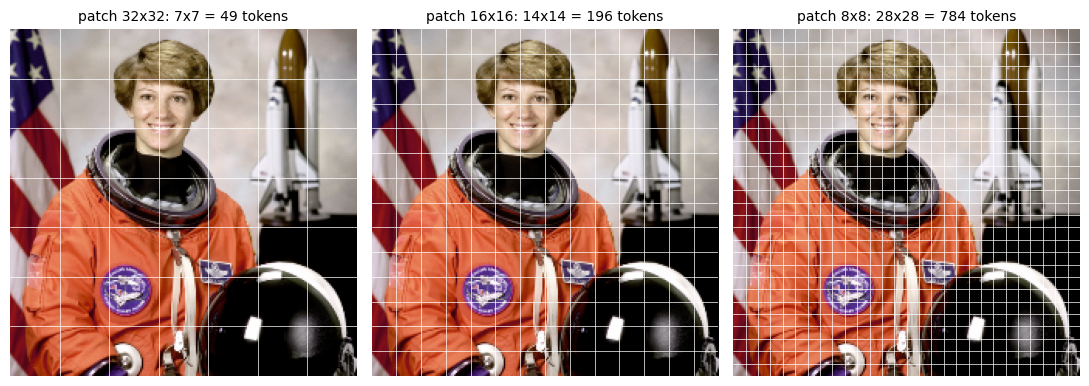

In [12]:
astro = skdata.astronaut()  # 512x512 RGB photograph bundled with scikit-image
img224 = F.interpolate(torch.from_numpy(astro).permute(2, 0, 1).float()[None] / 255, size=(224, 224), mode="bilinear", align_corners=False)[0]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, p in zip(axes, [32, 16, 8]):
    ax.imshow(img224.permute(1, 2, 0).numpy())
    g = 224 // p
    for t in range(1, g):
        ax.axhline(t * p - 0.5, color="w", lw=0.5)
        ax.axvline(t * p - 0.5, color="w", lw=0.5)
    ax.set_title(f"patch {p}x{p}: {g}x{g} = {g * g} tokens", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [13]:
def patchify(x: torch.Tensor, p: int) -> torch.Tensor:
    """(B, C, H, W) -> (B, N, C*p*p): cut into non-overlapping p x p tiles and flatten each tile."""
    B, C, H, W = x.shape
    assert H % p == 0 and W % p == 0, f"image {H}x{W} is not divisible by patch size {p}"  # the #1 from-scratch error (§8.4, §11)
    t = x.unfold(2, p, p).unfold(3, p, p)  # (B, C, H/p, W/p, p, p)
    return t.permute(0, 2, 3, 1, 4, 5).reshape(B, (H // p) * (W // p), C * p * p)


tiles = patchify(img224[None], 16)
print(f"[measured] 224x224x3 image, 16x16 patches -> {tuple(tiles.shape)} = (batch, tokens, numbers per token); 14x14 = {14 * 14} tokens, each 16*16*3 = {16 * 16 * 3} numbers")
try:
    patchify(torch.zeros(1, 3, 30, 30), 16)
except AssertionError as e:
    print("a 30x30 image with 16x16 patches is refused ->", e)

[measured] 224x224x3 image, 16x16 patches -> (1, 196, 768) = (batch, tokens, numbers per token); 14x14 = 196 tokens, each 16*16*3 = 768 numbers
a 30x30 image with 16x16 patches is refused -> image 30x30 is not divisible by patch size 16


### 3.2 "Flatten and project" is the same thing as ONE strided convolution (§3.2)
The notes make a neat point: multiplying each flattened patch by a matrix gives *exactly* the same numbers as a convolution whose kernel size and stride both equal the patch size. So the first operation of a "pure" ViT is, mechanically, **a single convolution** — applied once, not slid across many layers. We verify that on the real tile tensor above. `[measured]`

In [14]:
seed_all()
d_model = 768
proj = nn.Linear(768, d_model)  # explicit version: flatten -> matrix multiply
conv = nn.Conv2d(3, d_model, kernel_size=16, stride=16)  # convolution version
with torch.no_grad():
    conv.weight.copy_(proj.weight.view(d_model, 3, 16, 16))  # same weights, reshaped
    conv.bias.copy_(proj.bias)
tok_linear = proj(tiles)  # (1, 196, 768)
tok_conv = conv(img224[None]).flatten(2).transpose(1, 2)  # (1, 196, 768)
print(f"[measured] max |linear-projection - strided-convolution| = {float((tok_linear - tok_conv).abs().max()):.2e}  -> the two are the same operation")
print(f"parameters in the patch-embedding layer: {n_params(proj):,} (= 768*768 + 768)")

[measured] max |linear-projection - strided-convolution| = 2.15e-06  -> the two are the same operation
parameters in the patch-embedding layer: 590,592 (= 768*768 + 768)


### 3.3 Convolution layer vs patch embedding (§3.3) — `[from the notes]`
| | Convolution layer | Patch embedding |
|---|---|---|
| Output | still a 2-D grid of features | a flat **list** of tokens |
| Weight reuse | slides over many positions | applied once per patch |
| 2-D neighbour information afterwards | kept automatically | **lost** — must be restored (Part 4) |
| What one output unit sees | local, grows with depth | one whole patch, immediately |

### 3.4 Patch size is a design choice — with a quadratic price (§3.4)
Smaller patches keep finer detail but make a **longer sequence**; attention cost grows with the *square* of the sequence length. We reproduce the notes' checkpoint table by arithmetic, then add the attention-cost ratio. `[computed]`

In [15]:
rows = []
base_n = (224 // 32) ** 2
for name, p, res in [("ViT-Base/32", 32, 224), ("ViT-Base/16", 16, 224), ("ViT-Base/16 (high-res)", 16, 384), ("ViT-Base/8", 8, 224)]:
    n = (res // p) ** 2
    rows.append([name, f"{p}x{p}", f"{res}x{res}", f"{n} (+[CLS] = {n + 1})", f"{n * n:,}", f"{(n / base_n) ** 2:.0f}x"])
table(rows, ["checkpoint", "patch", "resolution", "tokens", "attention pairs N^2", "attention cost vs /32"])
print("\n[computed] /16 -> /8 at 224: tokens x4, attention x16 (the notes' worked example); /32 -> /16: tokens x4 also.")

checkpoint              patch  resolution  tokens              attention pairs N^2  attention cost vs /32
----------------------  -----  ----------  ------------------  -------------------  ---------------------
ViT-Base/32             32x32  224x224     49 (+[CLS] = 50)    2,401                1x                   
ViT-Base/16             16x16  224x224     196 (+[CLS] = 197)  38,416               16x                  
ViT-Base/16 (high-res)  16x16  384x384     576 (+[CLS] = 577)  331,776              138x                 
ViT-Base/8              8x8    224x224     784 (+[CLS] = 785)  614,656              256x                 

[computed] /16 -> /8 at 224: tokens x4, attention x16 (the notes' worked example); /32 -> /16: tokens x4 also.


### 3.5 Overlapping patches and small images (§3.5, §B of the PP16 brief)
* **Overlapping patches** use a stride *smaller* than the patch (like a CNN stride). More tokens, smoother coverage of features that straddle a tile border, higher cost; hybrid models (Day 39) use a small convolution at this stage for the same reason.
* **Small images need small patches.** A 32×32 CIFAR image cut into 16×16 patches gives only 4 tokens — too few for attention to do anything interesting. Our Fashion-MNIST images are 28×28, so we will use **4×4 patches (49 tokens)** or 7×7 (16 tokens). `[computed]`

In [16]:
n_overlap = ((224 - 16) // 8 + 1) ** 2
print(f"overlapping 16x16 patches with stride 8 on 224x224: {((224 - 16) // 8 + 1)}x{((224 - 16) // 8 + 1)} = {n_overlap} tokens (vs 196 non-overlapping)")
table([[p, f"{28 // p}x{28 // p}", (28 // p) ** 2, (28 // p) ** 2 + 1] for p in (14, 7, 4)], ["patch size on a 28x28 image", "grid", "tokens", "with [CLS]"])
print("CIFAR 32x32: patch 16 ->", (32 // 16) ** 2, "tokens | patch 8 ->", (32 // 8) ** 2, "| patch 4 ->", (32 // 4) ** 2)

overlapping 16x16 patches with stride 8 on 224x224: 27x27 = 729 tokens (vs 196 non-overlapping)
patch size on a 28x28 image  grid  tokens  with [CLS]
---------------------------  ----  ------  ----------
14                           2x2   4       5         
7                            4x4   16      17        
4                            7x7   49      50        
CIFAR 32x32: patch 16 -> 4 tokens | patch 8 -> 16 | patch 4 -> 64


# Part 4 — Position embeddings and the [CLS] token (§4)
### 🧒 In simple words
Self-attention treats its tokens like **a bag of cards**: it compares every card with every other, but it has no idea which card was first or which sat in the top-left corner. Shuffle the cards and the answer for the whole bag is unchanged. For text ("dog bites man" ≠ "man bites dog") and for images (an eye above a mouth ≠ a mouth above an eye) that is a disaster, so we **add a position vector to every token** before the first block.

### 4.1 Prove it: attention cannot see order
We build a small stack of encoder blocks and feed it 16 patch tokens plus a [CLS] token. Then we **shuffle the patches** and look at the [CLS] output. `[measured]`

In [17]:
seed_all()
D, NT = 32, 16
stack = nn.Sequential(*[Block(D, 4) for _ in range(3)]).eval()
cls_tok = torch.randn(1, 1, D)
patches = torch.randn(1, NT, D)
pos = torch.randn(1, NT + 1, D)  # a (random, but fixed) position vector for every slot incl. CLS
perm = torch.randperm(NT)


def cls_out(p: torch.Tensor, use_pos: bool) -> torch.Tensor:
    x = torch.cat([cls_tok, p], 1)
    if use_pos:
        x = x + pos
    with torch.no_grad():
        return stack(x)[:, 0]


d_no = float((cls_out(patches, False) - cls_out(patches[:, perm], False)).abs().max())
d_yes = float((cls_out(patches, True) - cls_out(patches[:, perm], True)).abs().max())
print(f"[measured] shuffle the patches, NO position embedding : change in [CLS] output = {d_no:.2e}  (identical -> order is invisible)")
print(f"[measured] shuffle the patches, WITH position embedding: change in [CLS] output = {d_yes:.2e}  (different -> order now matters)")

[measured] shuffle the patches, NO position embedding : change in [CLS] output = 2.38e-07  (identical -> order is invisible)
[measured] shuffle the patches, WITH position embedding: change in [CLS] output = 9.23e-02  (different -> order now matters)


**Reading the result.** Without positions the output changes by about 2e-7 (floating-point noise): the network literally cannot tell a jigsaw puzzle from its solution. With positions the output changes by an ordinary amount. This is why position information is **mandatory**, not an optional improvement (§4.1).

### 4.2 Two ways to build a position vector (§4.2)
* **Fixed (sinusoidal):** a formula of sines and cosines at different frequencies (the original transformer). No training, works for any length.
* **Learned:** simply a table of N+1 trainable vectors, updated by gradient descent like any weights (the original ViT). Tied to the training grid size → resolution changes need interpolation (Part 8).

Below: the sinusoidal pattern for 14 positions × 64 dimensions. Each row is a position's "address"; nearby positions have similar addresses. `[computed]`

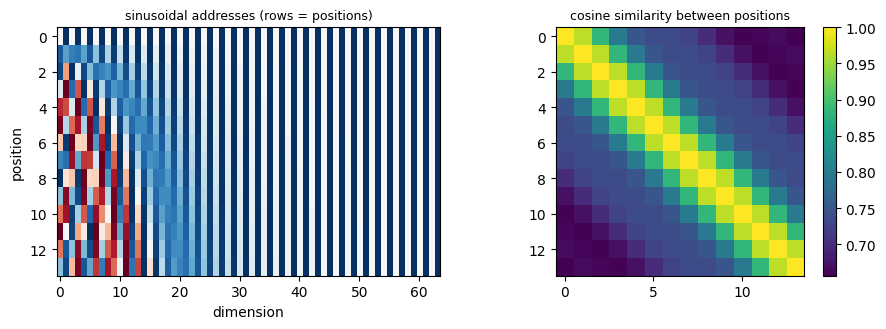

[measured] similarity of position 0 with 1, 2, 7, 13: [0.97, 0.88, 0.73, 0.66]  (falls with distance, no training needed)


In [18]:
def sinusoidal(n: int, d: int) -> torch.Tensor:
    pos_ = torch.arange(n).float()[:, None]
    i = torch.arange(0, d, 2).float()[None]
    ang = pos_ / (10000 ** (i / d))
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = ang.sin(), ang.cos()
    return pe


pe = sinusoidal(14, 64)
sim = F.normalize(pe, dim=1) @ F.normalize(pe, dim=1).T
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].imshow(pe.numpy(), cmap="RdBu", aspect="auto")
ax[0].set_title("sinusoidal addresses (rows = positions)", fontsize=9)
ax[0].set_xlabel("dimension")
ax[0].set_ylabel("position")
im = ax[1].imshow(sim.numpy(), cmap="viridis")
ax[1].set_title("cosine similarity between positions", fontsize=9)
plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout()
plt.show()
print(f"[measured] similarity of position 0 with 1, 2, 7, 13: {[round(float(sim[0, j]), 2) for j in (1, 2, 7, 13)]}  (falls with distance, no training needed)")

### 4.3 Research spotlight (§4.3): a *learned* table discovers 2-D geometry on its own
A learned position table is just 197 free vectors. Nobody told it that tile (3, 5) is next to tile (3, 6) — yet in the trained ViT the notes report that nearby tiles end up with similar vectors. We can check this on the **real pretrained ViT-B/16** (loaded in Part 0). For several chosen tiles we plot the cosine similarity between that tile's position vector and all 14×14 others. `[measured]` (requires the pretrained weights)

learned position table: (197, 768) = 1 [CLS] + 14x14 tiles, each 768-dim


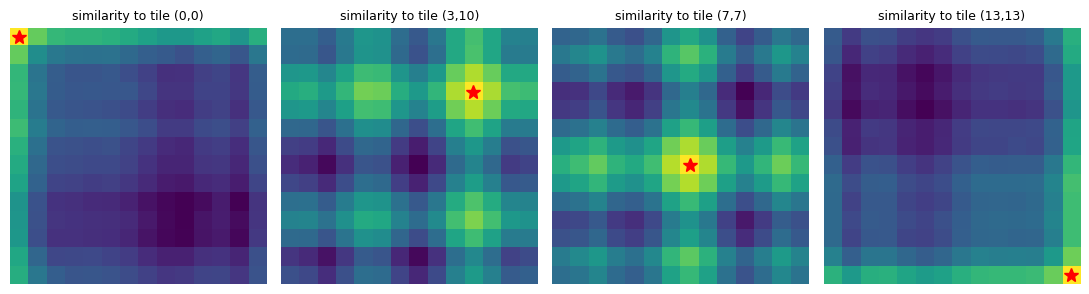

[measured] mean cosine similarity: adjacent tiles 0.775 | tiles 6+ steps apart -0.071


In [19]:
if HAVE_VITB:
    sd_b = torch.load(DATA_DIR / "jx_vit_base_p16_224.pth", map_location="cpu", weights_only=True)
    pe_b = sd_b["pos_embed"][0]  # (197, 768): row 0 is [CLS], then 14x14 tiles in row-major order
    grid_pe = F.normalize(pe_b[1:], dim=1)
    print(f"learned position table: {tuple(pe_b.shape)} = 1 [CLS] + 14x14 tiles, each 768-dim")
    picks = [(0, 0), (3, 10), (7, 7), (13, 13)]
    fig, axes = plt.subplots(1, len(picks), figsize=(11, 3.1))
    for ax, (r, c) in zip(axes, picks):
        s = (grid_pe[r * 14 + c] @ grid_pe.T).reshape(14, 14)
        ax.imshow(s.numpy(), cmap="viridis")
        ax.plot(c, r, "r*", ms=10)
        ax.set_title(f"similarity to tile ({r},{c})", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    # quantify: similarity of a tile with its 4-neighbours versus with tiles >= 6 steps away
    g = grid_pe.reshape(14, 14, -1)
    near, far = [], []
    for r in range(14):
        for c in range(14):
            for r2 in range(14):
                for c2 in range(14):
                    dd = abs(r - r2) + abs(c - c2)
                    if dd == 1:
                        near.append(float(g[r, c] @ g[r2, c2]))
                    elif dd >= 6:
                        far.append(float(g[r, c] @ g[r2, c2]))
    print(f"[measured] mean cosine similarity: adjacent tiles {np.mean(near):.3f} | tiles 6+ steps apart {np.mean(far):.3f}")
else:
    print("pretrained weights unavailable -> skipping the learned-position-embedding inspection")

**Reading the figure.** Each map is brightest around the starred tile and fades with distance, and there are also fainter bands along the starred tile's own row and column (a cross-shaped pattern): the table has *learned* 2-D row/column structure from data alone. The numbers confirm it (adjacent tiles are much more similar than distant ones). Caveat: this is one pretrained checkpoint and a *similarity* statistic — it shows that geometry is **encoded**, not how the attention layers use it.

### 4.4 The [CLS] token vs. average pooling (§4.4)
The ViT needs **one vector** to feed the classifier, but it has 196 tile-tokens. Two ways:
* **[CLS] token:** prepend one extra *learned* token. Through attention it can read from every tile; after the last block its output is the image summary. (Borrowed from BERT.)
* **Global average pooling (GAP):** just average the 196 outputs. No special token.

The notes say the two reach comparable accuracy and that GAP is sometimes a bit more stable when training from scratch. We will implement **both** in the MiniViT of Part 5 (`pool="cls"` / `"gap"`) and compare them in Part 6/7. `[from the notes]` — untested until then.

### 4.5 Beyond a plain table (§4.5) — `[from the notes]`
* **2-D position embeddings:** separate row and column vectors added together, so the model knows the grid shape.
* **Relative position encodings:** encode *how far apart* two tokens are rather than where each is absolutely; this transfers more naturally to new image sizes. Swin (Day 39) uses a relative bias added to the attention scores.

A tiny demo of the relative idea: a **learned bias added to the scores that depends only on (Δrow, Δcol)** — so the same bias is reused at every location, like a convolution's shared kernel. `[computed]`

In [20]:
class RelBias2D(nn.Module):
    """Learned score bias indexed by the (d_row, d_col) offset between two tiles on a g x g grid."""

    def __init__(self, g: int) -> None:
        super().__init__()
        self.g = g
        self.table = nn.Parameter(torch.zeros((2 * g - 1) ** 2))
        ys, xs = torch.meshgrid(torch.arange(g), torch.arange(g), indexing="ij")
        co = torch.stack([ys.flatten(), xs.flatten()])  # (2, N)
        rel = co[:, :, None] - co[:, None, :] + (g - 1)  # (2, N, N), non-negative
        self.register_buffer("idx", rel[0] * (2 * g - 1) + rel[1])

    def forward(self) -> torch.Tensor:  # (N, N) bias to add to the attention scores
        return self.table[self.idx]


rb = RelBias2D(4)
print(f"bias table has {rb.table.numel()} numbers (= (2*4-1)^2 offsets) but controls all {rb().numel()} tile pairs")
same = bool((rb.idx[0, 1] == rb.idx[5, 6]) and (rb.idx[0, 4] == rb.idx[9, 13]))
print(f"[measured] pairs with the same offset share one parameter: {same}")

bias table has 49 numbers (= (2*4-1)^2 offsets) but controls all 256 tile pairs
[measured] pairs with the same offset share one parameter: True


# Part 5 — The full ViT: encoder stack, [CLS] head, parameter counts (§5)
### 🧒 In simple words
Put the pieces from Parts 2–4 in a row and you have a ViT:

`image → patches → linear projection → + [CLS] token → + position vectors → L × encoder block → LayerNorm → take [CLS] → linear classifier → class scores`

Every encoder block keeps the table size **(N+1) × d**. Only the final tiny head turns it into class scores. The 12 (or 24, or 32) stacked blocks are where *all* the "thinking" happens.

### 5.1 Build it from scratch — `MiniViT`
Re-uses our own `MHSA` and `Block`. It has switches we will need later: pooling type (`cls` / `gap`), an optional DeiT-style distillation token (Part 7), and — only for the debugging demo of Part 11 — deliberate-bug switches.

In [21]:
class MiniViT(nn.Module):
    def __init__(self, img: int = 28, patch: int = 4, in_ch: int = 1, d: int = 64, depth: int = 4, heads: int = 4, n_cls: int = 10,
                 pool: str = "cls", drop: float = 0.0, drop_path: float = 0.0, distill: bool = False,
                 use_pos: bool = True, scale: bool = True, residual: bool = True) -> None:
        super().__init__()
        assert img % patch == 0, f"image size {img} must be divisible by patch size {patch}"
        assert pool in ("cls", "gap")
        self.patch, self.pool, self.distill, self.g = patch, pool, distill, img // patch
        n = self.g * self.g
        self.embed = nn.Conv2d(in_ch, d, patch, patch)  # patch embedding as ONE strided conv (Part 3)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.dist = nn.Parameter(torch.zeros(1, 1, d)) if distill else None
        self.n_extra = 1 + int(distill)
        self.pos = nn.Parameter(torch.zeros(1, n + self.n_extra, d)) if use_pos else None
        self.blocks = nn.ModuleList([Block(d, heads, 4, drop, drop_path * i / max(depth - 1, 1), scale, residual) for i in range(depth)])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, n_cls)
        self.head_dist = nn.Linear(d, n_cls) if distill else None
        nn.init.trunc_normal_(self.cls, std=0.02)
        if self.dist is not None:
            nn.init.trunc_normal_(self.dist, std=0.02)
        if self.pos is not None:
            nn.init.trunc_normal_(self.pos, std=0.02)
        self.apply(self._init)

    @staticmethod
    def _init(m: nn.Module) -> None:
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            nn.init.zeros_(m.bias)

    def tokens(self, x: torch.Tensor) -> torch.Tensor:
        t = self.embed(x).flatten(2).transpose(1, 2)  # (B, N, d)
        extra = [self.cls.expand(len(t), -1, -1)] + ([self.dist.expand(len(t), -1, -1)] if self.dist is not None else [])
        t = torch.cat(extra + [t], 1)
        return t + self.pos if self.pos is not None else t

    def features(self, x: torch.Tensor) -> torch.Tensor:
        t = self.tokens(x)
        for b in self.blocks:
            t = b(t)
        return self.norm(t)  # (B, N + extra, d)

    def forward(self, x: torch.Tensor):
        f = self.features(x)
        summary = f[:, 0] if self.pool == "cls" else f[:, self.n_extra:].mean(1)
        if not self.distill:
            return self.head(summary)
        out_c, out_d = self.head(summary), self.head_dist(f[:, 1])
        return (out_c, out_d) if self.training else (out_c + out_d) / 2

    def attention_maps(self) -> list[torch.Tensor]:
        return [b.attn.last_attn for b in self.blocks]  # each (B, heads, N, N), filled by the last forward pass


seed_all()
m = MiniViT()
xb = torch.randn(2, 1, 28, 28)
print(f"MiniViT: {n_params(m):,} parameters | 28x28 image, 4x4 patches -> {m.g}x{m.g} = {m.g ** 2} tokens + [CLS] = {m.g ** 2 + 1}")
print("tokens after embedding:", tuple(m.tokens(xb).shape), "| after the 4 blocks:", tuple(m.features(xb).shape), "| logits:", tuple(m(xb).shape))

MiniViT: 205,066 parameters | 28x28 image, 4x4 patches -> 7x7 = 49 tokens + [CLS] = 50
tokens after embedding: (2, 50, 64) | after the 4 blocks: (2, 50, 64) | logits: (2, 10)


### 5.2 Unit tests on toy inputs (§8.6 — "test the pieces before you train")
A from-scratch ViT fails *silently*: a wrong shape that happens to broadcast, a frozen layer or a missing residual still "trains", just badly. So we assert the things that must be true. `[measured]` — an `AssertionError` would stop the notebook.

In [22]:
def run_unit_tests(model_fn, verbose: bool = True) -> dict[str, bool]:
    """Returns {test name: passed}. Used on the good model here and on deliberately broken ones in Part 11."""
    seed_all()
    res: dict[str, bool] = {}
    model = model_fn()
    x = torch.randn(4, 1, 28, 28)
    y = torch.tensor([0, 1, 2, 3])
    # 1. shapes
    res["output shape = (batch, classes)"] = tuple(model(x).shape) == (4, 10)
    res["token count = (28/4)^2 + 1"] = tuple(model.tokens(x).shape) == (4, 50, model.embed.out_channels)
    # 2. no NaN / inf
    res["finite outputs"] = bool(torch.isfinite(model(x)).all())
    # 3. every parameter receives a gradient
    model.zero_grad()
    F.cross_entropy(model(x), y).backward()
    dead = [n for n, p in model.named_parameters() if p.grad is None or float(p.grad.abs().sum()) == 0.0]
    res["gradient reaches every parameter"] = not dead
    # 4. attention rows sum to 1
    res["attention rows sum to 1"] = all(torch.allclose(a.sum(-1), torch.ones_like(a.sum(-1)), atol=1e-4) for a in model.attention_maps())
    # 5. can it overfit 4 images? (a model that cannot is broken or has no capacity)
    model2 = model_fn()
    opt = torch.optim.AdamW(model2.parameters(), lr=3e-3)
    first = None
    for _ in range(60):
        opt.zero_grad()
        loss = F.cross_entropy(model2(x), y)
        first = first if first is not None else float(loss)
        loss.backward()
        opt.step()
    res["overfits a 4-image batch"] = float(loss) < 0.3 * first
    # 6. eval mode is deterministic
    model.eval()
    res["eval mode deterministic"] = bool(torch.allclose(model(x), model(x)))
    if verbose:
        for k, v in res.items():
            print(f"  [{'PASS' if v else 'FAIL'}] {k}")
        if dead:
            print("  parameters without gradient:", dead[:4])
    return res


good = run_unit_tests(lambda: MiniViT())
assert all(good.values()), "the reference MiniViT must pass every test"

  [PASS] output shape = (batch, classes)
  [PASS] token count = (28/4)^2 + 1
  [PASS] finite outputs
  [PASS] gradient reaches every parameter
  [PASS] attention rows sum to 1
  [PASS] overfits a 4-image batch
  [PASS] eval mode deterministic


### 5.3 How big are real ViTs? (§5.2) — parameter counts
We instantiate each architecture on PyTorch's **meta device** (shapes only, no memory used) and count parameters, next to two famous CNNs. `[measured]`, compared with the notes' approximate figures `[from the notes]`.

In [23]:
import timm  # noqa: E402
import torchvision  # noqa: E402

rows = []
notes_val = {"ViT-Small/16": "~22 M", "ViT-Base/16": "~86 M", "ViT-Large/16": "~307 M", "ViT-Huge/14": "~632 M", "ResNet-152": "~60 M", "EfficientNet-B5": "~30 M"}
with torch.device("meta"):
    zoo = {
        "ViT-Small/16": (timm.create_model("vit_small_patch16_224", pretrained=False), "L=12, d=384, 6 heads"),
        "ViT-Base/16": (timm.create_model("vit_base_patch16_224", pretrained=False), "L=12, d=768, 12 heads"),
        "ViT-Large/16": (timm.create_model("vit_large_patch16_224", pretrained=False), "L=24, d=1024, 16 heads"),
        "ViT-Huge/14": (timm.create_model("vit_huge_patch14_224", pretrained=False), "L=32, d=1280, 16 heads"),
        "ResNet-152": (torchvision.models.resnet152(), "CNN"),
        "EfficientNet-B5": (torchvision.models.efficientnet_b5(), "CNN"),
    }
for name, (mod, cfg) in zoo.items():
    rows.append([name, cfg, f"{n_params(mod) / 1e6:.1f} M", notes_val[name]])
table(rows, ["model", "configuration", "parameters (counted here)", "notes say"])
vb = zoo["ViT-Base/16"][0]
blk_p = n_params(vb.blocks[0])
print(f"\nViT-B/16 anatomy [measured]: patch embedding {n_params(vb.patch_embed) / 1e6:.2f} M | one block {blk_p / 1e6:.2f} M x 12 = {12 * blk_p / 1e6:.1f} M | position+CLS {(vb.pos_embed.numel() + vb.cls_token.numel()) / 1e6:.2f} M | head {n_params(vb.head) / 1e6:.2f} M")
print("-> almost all weights sit in the encoder blocks; the patch layer and the classifier are tiny.")
del zoo, vb

model            configuration           parameters (counted here)  notes say
---------------  ----------------------  -------------------------  ---------
ViT-Small/16     L=12, d=384, 6 heads    22.1 M                     ~22 M    
ViT-Base/16      L=12, d=768, 12 heads   86.6 M                     ~86 M    
ViT-Large/16     L=24, d=1024, 16 heads  304.3 M                    ~307 M   
ViT-Huge/14      L=32, d=1280, 16 heads  630.8 M                    ~632 M   
ResNet-152       CNN                     60.2 M                     ~60 M    
EfficientNet-B5  CNN                     30.4 M                     ~30 M    

ViT-B/16 anatomy [measured]: patch embedding 0.59 M | one block 7.09 M x 12 = 85.1 M | position+CLS 0.15 M | head 0.77 M
-> almost all weights sit in the encoder blocks; the patch layer and the classifier are tiny.


**Reading the table.** The counts agree with the notes' approximate values to within about 1 %. Note a ViT-B (≈86 M) has *more* parameters than ResNet-152 (≈60 M) yet that is not what makes it data-hungry — Part 6 shows the missing *prior knowledge* is what matters, not raw size. (Parameter count is also not compute: ViT-B/16 at 224 px needs far more FLOPs than a small CNN with equal parameters because every token passes through every weight.)

### 5.4 A traced forward pass through the real ViT-B/16 (§5.4)
We push one 224×224 photo through the pretrained ViT-B/16 and print the tensor shape after each stage, using hooks. The shape is the notes' **197 × 768** until the very last step. `[measured]`

In [24]:
if HAVE_VITB:
    vit_b = make_vit_b().eval()
    seen: list[tuple[str, tuple]] = []
    hooks = [
        vit_b.patch_embed.register_forward_hook(lambda m_, i_, o_: seen.append(("patch embedding (196 tiles x 768)", tuple(o_.shape)))),
        vit_b.norm_pre.register_forward_hook(lambda m_, i_, o_: seen.append(("+ [CLS] + position embeddings", tuple(o_.shape)))),
        vit_b.blocks[0].register_forward_hook(lambda m_, i_, o_: seen.append(("after block 1", tuple(o_.shape)))),
        vit_b.blocks[5].register_forward_hook(lambda m_, i_, o_: seen.append(("after block 6", tuple(o_.shape)))),
        vit_b.blocks[11].register_forward_hook(lambda m_, i_, o_: seen.append(("after block 12", tuple(o_.shape)))),
        vit_b.norm.register_forward_hook(lambda m_, i_, o_: seen.append(("final LayerNorm", tuple(o_.shape)))),
        vit_b.head.register_forward_hook(lambda m_, i_, o_: seen.append(("classifier on the [CLS] vector only", tuple(o_.shape)))),
    ]
    with torch.no_grad():
        vit_b((img224[None] - 0.5) / 0.5)
    for h in hooks:
        h.remove()
    table([[a, str(b)] for a, b in seen], ["stage", "tensor shape"])
else:
    print("pretrained ViT-B not available -> skipping the traced pass")

stage                                tensor shape 
-----------------------------------  -------------
patch embedding (196 tiles x 768)    (1, 196, 768)
+ [CLS] + position embeddings        (1, 197, 768)
after block 1                        (1, 197, 768)
after block 6                        (1, 197, 768)
after block 12                       (1, 197, 768)
final LayerNorm                      (1, 197, 768)
classifier on the [CLS] vector only  (1, 1000)    


**Reading the output.** The "pre-norm" hook shows `(1, 197, 768)`: 196 tiles + [CLS], 768 numbers each. Every block returns the same shape. Only the classifier changes it, and it reads *one* row — the [CLS] vector — which is why that token must have gathered a summary of the whole image by block 12.

### 5.5 The memory cost of attention maps (§5.5)
Each block stores an N×N weight matrix **per head** (needed for the backward pass). For ViT-B (12 heads, 12 blocks), fp32: `[computed]`

In [25]:
rows = []
for name, n in [("224px, patch 32", 50), ("224px, patch 16", 197), ("384px, patch 16", 577), ("224px, patch 8", 785), ("512px, patch 16", 1025)]:
    one = n * n * 4  # bytes, one head one layer, per image
    rows.append([name, n, f"{one / 1e6:.2f} MB", f"{one * 12 * 12 / 1e6:.0f} MB"])
table(rows, ["setting", "tokens (+CLS)", "one head, one layer", "all 12 heads x 12 layers, per image"])
print("at 512px a SINGLE image's attention maps already need about", f"{1025 * 1025 * 4 * 144 / 1e9:.2f} GB (fp32) - why gradient accumulation / memory-aware attention matter (Parts 8, 10)")

setting          tokens (+CLS)  one head, one layer  all 12 heads x 12 layers, per image
---------------  -------------  -------------------  -----------------------------------
224px, patch 32  50             0.01 MB              1 MB                               
224px, patch 16  197            0.16 MB              22 MB                              
384px, patch 16  577            1.33 MB              192 MB                             
224px, patch 8   785            2.46 MB              355 MB                             
512px, patch 16  1025           4.20 MB              605 MB                             
at 512px a SINGLE image's attention maps already need about 0.61 GB (fp32) - why gradient accumulation / memory-aware attention matter (Parts 8, 10)


# Part 6 — ViT vs. CNN: inductive bias and the data question (§6)
### 🧒 In simple words
Teach a child to recognise cats and you never have to say *"nearby pixels belong together"* or *"a cat in the left of the picture is still a cat when it is in the right"* — but a **CNN has those two rules built in**, whereas a **ViT has to discover them from examples**.
* **Locality** — a convolution only looks at a small neighbourhood.
* **Translation equivariance** — the same filter slides everywhere, so a shifted input gives a shifted feature map. (Equivariance = the output moves with the input; invariance = the output does not change at all.)

These built-in assumptions are called **inductive bias**. Bias sounds bad, but here it is *free knowledge*: with little data it helps a lot. With a **huge** amount of data, a model without those rules can learn better ones than we could write down — the notes' "crossover" idea (§6.3).

So the claim to test is **"a from-scratch ViT needs more data than a CNN to do equally well"**. We measure it directly.

### 6.1 The experiment (read this before the numbers)
* Data: Fashion-MNIST, a random training subset of size **n ∈ {250, 1000, 4000, 16000}**; the **same** 3 000 test images for every model.
* **CNN** — 3 conv layers (≈24 k parameters). **ViT** — our `MiniViT` (4×4 patches → 49 tokens, d=64, 4 blocks, ≈205 k parameters).
* Same optimiser family (AdamW), same batch size, cosine schedule, **no data augmentation** for either (Part 7 adds it), a number of gradient steps that grows with n (so small sets are seen many times).
* 2 seeds per cell; the table shows the mean and the two values' spread.
* ⚠️ **Limits**: tiny models, a very easy dataset, two seeds, hyper-parameters not tuned per size. This tests the *direction* of the effect, not its size on ImageNet-scale problems. The ViT has ~8× more parameters than the CNN; Part 6.4 comments on why that does not explain the result by itself — and the measured result is in 6.2 (the 8×-larger ViT is behind at every size)..

In [26]:
def make_cnn(n_cls: int = 10, width: int = 16) -> nn.Module:
    w = width
    return nn.Sequential(
        nn.Conv2d(1, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(w, 2 * w, 3, padding=1), nn.BatchNorm2d(2 * w), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(2 * w, 4 * w, 3, padding=1), nn.BatchNorm2d(4 * w), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(4 * w, n_cls))


def lr_at(step: int, steps: int, base: float, warmup: float, sched: str = "cosine") -> float:
    """Linear warmup for the first `warmup` fraction, then cosine decay to ~0 (Day 38 section 7.5)."""
    w = int(warmup * steps)
    if step < w:
        return base * (step + 1) / max(w, 1)
    if sched == "const":
        return base
    return 0.5 * base * (1 + math.cos(math.pi * (step - w) / max(steps - w, 1)))


@torch.no_grad()
def evaluate(model: nn.Module, X: torch.Tensor, Y: torch.Tensor, bs: int = 500) -> float:
    model.eval()
    ok = 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        out = out[0] if isinstance(out, tuple) else out
        ok += int((out.argmax(1) == Y[i:i + bs]).sum())
    return ok / len(X)


def fit(model: nn.Module, X: torch.Tensor, Y: torch.Tensor, steps: int, lr: float, wd: float = 0.05, warmup: float = 0.1, bs: int = 64,
        seed: int = 0, batch_tf=None, loss_fn=None, clip: float | None = 1.0, sched: str = "cosine", trace: bool = False):
    """Generic mini-batch trainer. `batch_tf(xb, yb) -> (xb, target)` for augmentation; `loss_fn(model, xb, target)` for custom losses."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    losses, lrs = [], []
    model.train()
    for s in range(steps):
        for pg in opt.param_groups:
            pg["lr"] = lr_at(s, steps, lr, warmup, sched)
        idx = torch.randint(0, len(X), (bs,), generator=g)
        xb, yb = X[idx], Y[idx]
        tgt = yb
        if batch_tf is not None:
            xb, tgt = batch_tf(xb, yb)
        if loss_fn is not None:
            loss = loss_fn(model, xb, tgt)
        else:
            loss = F.cross_entropy(model(xb), tgt)
        opt.zero_grad()
        loss.backward()
        if clip is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        opt.step()
        if trace:
            losses.append(float(loss))
            lrs.append(opt.param_groups[0]["lr"])
    model.eval()
    return (losses, lrs) if trace else None

In [27]:
SIZES = [250, 1000, 4000, 16000]
STEPS = {250: 300, 1000: 500, 4000: 800, 16000: 1200}
SEEDS = [0, 1]
NTEST = 3000
if QUICK:
    SIZES, STEPS, SEEDS, NTEST = [250, 1000], {250: 20, 1000: 20}, [0], 500

LC: dict[str, dict[int, list[float]]] = {"CNN": {}, "ViT": {}}
KEEP: dict[str, nn.Module] = {}  # models trained on the 4000-image set (seed 0), reused for the shift test
if HAVE_FM:
    t0 = time.time()
    xte, yte = XTE[:NTEST], YTE[:NTEST]
    for n in SIZES:
        for name in ("CNN", "ViT"):
            accs = []
            for sd in SEEDS:
                seed_all(100 + sd)
                mdl = make_cnn() if name == "CNN" else MiniViT(drop=0.0)
                lr = 3e-3 if name == "CNN" else 1e-3
                fit(mdl, XTR[:n], YTR[:n], STEPS[n], lr, wd=0.05, seed=sd)
                accs.append(evaluate(mdl, xte, yte))
                if n == 4000 and sd == 0:
                    KEEP[name] = mdl
            LC[name][n] = accs
        print(f"n={n:>6}:  CNN {np.mean(LC['CNN'][n]):.3f} {np.round(LC['CNN'][n], 3).tolist()}   ViT {np.mean(LC['ViT'][n]):.3f} {np.round(LC['ViT'][n], 3).tolist()}   (elapsed {time.time() - t0:.0f}s)")
    print("[measured] test accuracy, per-seed values in brackets;", f"CNN {n_params(make_cnn()):,} params, ViT {n_params(MiniViT()):,} params")

n=   250:  CNN 0.735 [0.731, 0.738]   ViT 0.612 [0.617, 0.607]   (elapsed 97s)
n=  1000:  CNN 0.808 [0.807, 0.809]   ViT 0.707 [0.725, 0.689]   (elapsed 252s)
n=  4000:  CNN 0.844 [0.843, 0.846]   ViT 0.772 [0.787, 0.757]   (elapsed 503s)
n= 16000:  CNN 0.868 [0.867, 0.869]   ViT 0.820 [0.821, 0.818]   (elapsed 874s)
[measured] test accuracy, per-seed values in brackets; CNN 24,170 params, ViT 205,066 params


### 6.2 The learning curves
`[measured]`

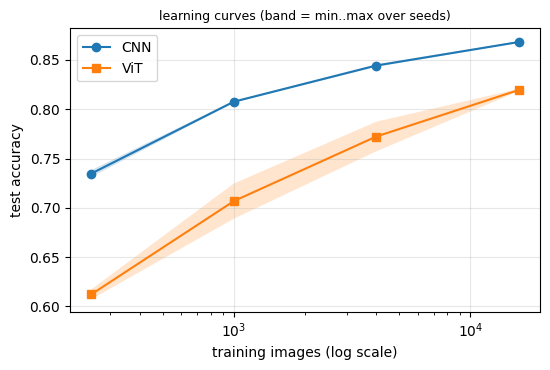

CNN minus ViT accuracy at each n: {250: 0.122, 1000: 0.101, 4000: 0.072, 16000: 0.049}


In [28]:
if HAVE_FM:
    fig, ax = plt.subplots(figsize=(5.6, 3.8))
    for name, mk in [("CNN", "o-"), ("ViT", "s-")]:
        mu = [np.mean(LC[name][n]) for n in SIZES]
        lo = [min(LC[name][n]) for n in SIZES]
        hi = [max(LC[name][n]) for n in SIZES]
        ax.plot(SIZES, mu, mk, label=name)
        ax.fill_between(SIZES, lo, hi, alpha=0.2)
    ax.set_xscale("log")
    ax.set_xlabel("training images (log scale)")
    ax.set_ylabel("test accuracy")
    ax.set_title("learning curves (band = min..max over seeds)", fontsize=9)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    gap = [np.mean(LC["CNN"][n]) - np.mean(LC["ViT"][n]) for n in SIZES]
    print("CNN minus ViT accuracy at each n:", dict(zip(SIZES, np.round(gap, 3).tolist())))

**Reading the curves** (`[measured]`, 2 seeds).
* The CNN is ahead at **every** training-set size: 0.735 vs 0.612 (250 images), 0.808 vs 0.707 (1 000), 0.844 vs 0.772 (4 000), 0.868 vs 0.820 (16 000).
* The gap **shrinks as data grows** — 12.2 → 10.1 → 7.2 → 4.9 points — which is the direction the notes predict (the ViT catches up when it has more examples to learn the missing structure from).
* The two seeds of each model differ by at most ~0.04 (ViT) and ~0.007 (CNN); every gap is much larger than that, so the ordering is not seed noise (but two seeds is still a small sample).
* The ViT has ~8× more parameters than the CNN and is *still* worse at every size — more weights did not buy data-efficiency.
* **What this does not show:** whether the curves would cross with more data. At 16 000 images (27 % of the training set) the ViT has not caught up; any claim about a crossover point would be extrapolation, i.e. speculation. Also, both models use one hand-picked recipe (the CNN has BatchNorm, the ViT does not); unequal tuning may account for part of the gap.

### 6.3 A "data multiplier": how many ViT images equal one CNN image? (§6.3 toy "k factor")
Pick a target accuracy that **both** curves reach, find (by linear interpolation in log-n) how many training images each model needs for it, and divide. This is a *rough* number from 4 points and 2 seeds; it is meant to give the idea of "k", not to be quoted. `[computed from the curves above]`

In [29]:
def n_needed(curve_mean: list[float], sizes: list[int], target: float) -> float | None:
    for i in range(len(sizes) - 1):
        a, b = curve_mean[i], curve_mean[i + 1]
        if a <= target <= b and b > a:
            f = (target - a) / (b - a)
            return float(np.exp(np.log(sizes[i]) + f * (np.log(sizes[i + 1]) - np.log(sizes[i]))))
    return float(sizes[0]) if curve_mean[0] >= target else None


if HAVE_FM and len(SIZES) >= 3:
    mc = [np.mean(LC["CNN"][n]) for n in SIZES]
    mv = [np.mean(LC["ViT"][n]) for n in SIZES]
    hi_common = min(max(mc), max(mv))
    rows = []
    for tgt in sorted({round(x, 3) for x in [min(mc[0], mv[0]) + 0.5 * (hi_common - min(mc[0], mv[0])), hi_common - 0.01]}):
        a, b = n_needed(mc, SIZES, tgt), n_needed(mv, SIZES, tgt)
        a_bound = mc[0] >= tgt  # the CNN already beats the target at the smallest size: its true need is <= that size
        rows.append([f"{tgt:.3f}", (f"<= {a:.0f}" if a_bound else f"{a:.0f}") if a else "not reached", f"{b:.0f}" if b else "not reached",
                     (f">= {b / a:.1f}x" if a_bound else f"{b / a:.1f}x") if a and b else "-"])
    table(rows, ["target test accuracy", "CNN images needed", "ViT images needed", "k = ViT / CNN"])

target test accuracy  CNN images needed  ViT images needed  k = ViT / CNN
--------------------  -----------------  -----------------  -------------
0.716                 <= 250             1214               >= 4.9x      
0.810                 1092               12102              11.1x        


**Reading the table** (`[computed]`).
* At the lower target (0.716) the ViT needs about 1 200 images, but the CNN had **already passed** that accuracy at our smallest size (250), so 250 is only an *upper bound* for the CNN: the true ratio is **at least** 4.9×.
* At the higher target (0.810) the CNN needs ≈ 1 100 and the ViT ≈ 12 000 images: **k ≈ 11×** (interpolated between the 4 000 and 16 000 points assuming a straight line in log-n, which is a coarse assumption).
* So k is not a constant — in this toy setting it was roughly 5× or more at one accuracy level and about 11× at a higher one. Treat it as *"the ViT needed several times to roughly ten times more data"* on this problem, not as a transferable number.

### 6.4 The other side of the ledger: is "more parameters" the explanation? And what does the bias cost? (§6.3)
* The ViT has ~8× more weights than the CNN, but weights alone cannot be the story: Part 5 showed ViT-B has 86 M parameters and still needs pretraining. What the CNN has is *structure*. We can test the claim directly by checking which kind of mistake each model makes when the input is moved.
* **The cost of the bias**: locality is a *ceiling* too — if the right answer needs far-apart pixels to be compared early, a small-window CNN cannot do it cheaply, whereas attention can. That cost does not show up on easy Fashion-MNIST, so we do not claim to measure it here. `[from the notes]`

### 6.5 Equivariance probe: shift every test image by a few pixels
Both models were trained on **centred, unshifted** images (the 4 000-image run above, seed 0). Now we slide each test image 1, 2, 3 pixels to the right (zero fill) and ask: how much accuracy is lost? A model that *learned or was built with* translation robustness loses little. `[measured]` — note the CNN ends in global average pooling, so it is nearly translation-invariant by design.

In [30]:
def shift_img(x: torch.Tensor, dx: int) -> torch.Tensor:
    out = torch.zeros_like(x)
    out[..., dx:] = x[..., : x.shape[-1] - dx] if dx > 0 else x
    return out


if HAVE_FM and "CNN" in KEEP:
    rows = []
    for dx in [0, 1, 2, 3, 5]:
        row = [f"{dx} px"]
        for name in ("CNN", "ViT"):
            row.append(f"{evaluate(KEEP[name], shift_img(xte, dx), yte):.3f}")
        rows.append(row)
    table(rows, ["shift of test images", "CNN accuracy", "ViT accuracy"])

shift of test images  CNN accuracy  ViT accuracy
--------------------  ------------  ------------
0 px                  0.843         0.787       
1 px                  0.830         0.667       
2 px                  0.794         0.496       
3 px                  0.809         0.350       
5 px                  0.746         0.243       


**Reading the table** (`[measured]`, one seed each, models trained **without** any shifted images).
* The CNN degrades gently: 0.843 → 0.830 (1 px) → 0.809 (3 px) → 0.746 (5 px).
* The ViT falls fast: 0.787 → 0.667 (1 px) → 0.350 (3 px) → 0.243 (5 px) — far below its clean accuracy even for a one-pixel move.
* This fits the idea of §6: the CNN's shared sliding filters and global pooling give translation robustness *for free*; the ViT's tiles and position vectors tie it to the exact pixel grid it saw, and 4 000 centred examples did not teach it otherwise.
* Cautions: (i) single seed; the CNN's own numbers are not perfectly monotonic (0.794 at 2 px, 0.809 at 3 px), so differences of a few points are noise; (ii) a 1-pixel shift also changes how the 4×4 patch grid cuts the object, an effect specific to patch-based models. Whether shift augmentation would repair this was **not** measured (Part 7.1 evaluates only on unshifted test images).

# Part 7 — Training a ViT: augmentation, regularisation, warmup, distillation, precision (§7)
### 🧒 In simple words
Part 6 showed a from-scratch ViT is hungry for data. The notes list the standard ways to *feed it more cheaply*:
1. **Augmentation** — show each picture in many slightly different versions (shifted, flipped, blended). *Mixup* blends two images and their labels; *CutMix* pastes a rectangle from one image onto another.
2. **Regularisation** — dropout (randomly silence units), weight decay (keep weights small), **stochastic depth** (randomly skip whole blocks).
3. **Warmup** — start with a tiny learning rate and ramp up, because the attention softmax is touchy early on.
4. **Distillation (DeiT)** — a CNN "teacher" labels the images, a ViT "student" learns from both the real labels and the teacher through an extra **distillation token**; the student inherits some of the CNN's bias.
5. **Transfer learning** — start from a pretrained model (Part 8) — by far the most common solution.
6. **Careful precision** — half-precision saves memory, but the softmax must stay in full precision.

We test each of these on the small problem. Everything below uses `fit()` from Part 6.

### 7.1 Augmentation and regularisation ablation (§7.2, §7.3)
Set-up `[assumed]`: MiniViT, **1 000** training images, 400 steps, 2 seeds, evaluated on the same 3 000 test images. Row 2 adds shift/flip to the baseline; rows 3 and 4 each add one more ingredient on top of row 2. A difference can only be attributed to the ingredient **if it is bigger than the seed-to-seed noise** (printed as ±range).

In [31]:
def rand_shift_flip(xb: torch.Tensor, yb: torch.Tensor, m: int = 2):
    """Random translation up to ±m pixels (zero fill) and horizontal flip, per image."""
    B = len(xb)
    pad = F.pad(xb, (m, m, m, m))
    out = torch.empty_like(xb)
    for i in range(B):
        dy, dx = np.random.randint(0, 2 * m + 1, 2)
        im = pad[i, :, dy:dy + 28, dx:dx + 28]
        out[i] = im.flip(-1) if np.random.rand() < 0.5 else im
    return out, yb


def mix_cut(xb: torch.Tensor, yb: torch.Tensor):
    """Mixup or CutMix (50/50 per batch); returns soft targets (B, 10)."""
    xb, yb = rand_shift_flip(xb, yb)
    y1 = F.one_hot(yb, 10).float()
    perm = torch.randperm(len(xb))
    if np.random.rand() < 0.5:  # mixup
        lam = float(np.random.beta(0.4, 0.4))
        return lam * xb + (1 - lam) * xb[perm], lam * y1 + (1 - lam) * y1[perm]
    lam = float(np.random.beta(1.0, 1.0))  # cutmix
    h = int(round(28 * math.sqrt(1 - lam)))
    cy, cx = np.random.randint(0, 28, 2)
    y0, y1_, x0, x1 = max(cy - h // 2, 0), min(cy + h // 2 + h % 2, 28), max(cx - h // 2, 0), min(cx + h // 2 + h % 2, 28)
    xb = xb.clone()
    xb[:, :, y0:y1_, x0:x1] = xb[perm][:, :, y0:y1_, x0:x1]
    lam_eff = 1 - (y1_ - y0) * (x1 - x0) / 784  # exact fraction kept, after clipping the box at the border
    return xb, lam_eff * y1 + (1 - lam_eff) * y1[perm]


def soft_ce(model: nn.Module, xb: torch.Tensor, tgt: torch.Tensor) -> torch.Tensor:
    return -(tgt * F.log_softmax(model(xb), -1)).sum(-1).mean()


ABL: dict[str, list[float]] = {}
if HAVE_FM:
    n_abl, steps_abl = (1000, 400) if not QUICK else (250, 20)
    configs = [
        ("baseline (no augmentation)", {}, None, None),
        ("+ random shift & flip", {}, rand_shift_flip, None),
        ("+ shift/flip + Mixup/CutMix", {}, mix_cut, soft_ce),
        ("+ shift/flip + dropout .1 + stoch. depth .1", {"drop": 0.1, "drop_path": 0.1}, rand_shift_flip, None),
    ]
    t0 = time.time()
    for name, kw, tf, lf in configs:
        accs = []
        for sd in SEEDS:
            seed_all(200 + sd)
            mdl = MiniViT(**kw)
            fit(mdl, XTR[:n_abl], YTR[:n_abl], steps_abl, 1e-3, wd=0.05, seed=sd, batch_tf=tf, loss_fn=lf)
            accs.append(evaluate(mdl, xte, yte))
        ABL[name] = accs
    base = np.mean(ABL["baseline (no augmentation)"])
    table([[k, f"{np.mean(v):.3f}", f"±{(max(v) - min(v)) / 2:.3f}", f"{np.mean(v) - base:+.3f}"] for k, v in ABL.items()],
          ["MiniViT, 1000 train images", "test acc (mean)", "seed spread", "vs baseline"])
    print(f"[measured] {len(SEEDS)} seeds each, {steps_abl} steps, {time.time() - t0:.0f}s")

MiniViT, 1000 train images                   test acc (mean)  seed spread  vs baseline
-------------------------------------------  ---------------  -----------  -----------
baseline (no augmentation)                   0.645            ±0.029       +0.000     
+ random shift & flip                        0.538            ±0.004       -0.107     
+ shift/flip + Mixup/CutMix                  0.451            ±0.018       -0.194     
+ shift/flip + dropout .1 + stoch. depth .1  0.540            ±0.008       -0.105     
[measured] 2 seeds each, 400 steps, 484s


**Reading the table** (`[measured]`, 2 seeds each, 400 steps).
* **Surprise:** all three additions *lowered* test accuracy in this set-up: baseline 0.645 (±0.029), + shift/flip 0.538, + Mixup/CutMix 0.451, + dropout/stochastic depth 0.540. The drops are much larger than the seed spread.
* This is **not** what one would conclude from the notes for a data-hungry ViT, and it does **not** refute them either: it is a result about *this budget*. Possible reasons (hypotheses, **not tested here**):
  1. Only 400 steps — regularised/augmented models learn more slowly and may simply be under-trained. A hint: the same 1 000-image ViT scored 0.707 in Part 6 with 500 steps (different seeds), versus 0.645 here with 400 — at this scale training length matters a lot.
  2. The test images are centred and unflipped; spending capacity on shifts/flips and blended images helps only if the test data needs those invariances.
  3. Mixup/CutMix targets are harder to fit quickly; dropout at 0.1 does little for a model this small.
* To test augmentation fairly one needs longer training and **train-vs-test accuracy curves** (to see whether the baseline is overfitting at all) — this notebook did not record training accuracy, so it cannot say whether the baseline was overfitting.
* Lesson for PP16: never assume a trick helps — run the ablation with *your* budget and report it, including when it hurts.

### 7.2 Learning-rate warmup (§7.5)
🧒 Right after random initialisation the attention weights are close to uniform and the gradients are unusually large and noisy. A big first step can throw the weights somewhere bad and the run never recovers. **Warmup** = start tiny and ramp up linearly, then decay (cosine). The notes' debugging story (§11.4): a Task-A run that "stalls at 10 % accuracy" had **no warmup**.

First the schedule itself `[computed]`:

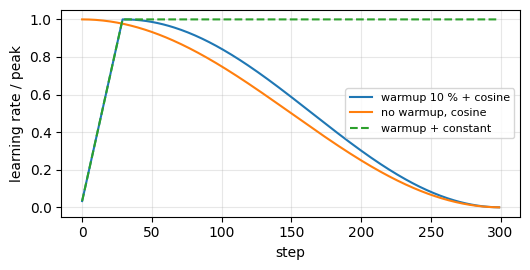

In [32]:
steps_demo = 300
fig, ax = plt.subplots(figsize=(5.4, 2.8))
for w, lab in [(0.1, "warmup 10 % + cosine"), (0.0, "no warmup, cosine"), (0.1, None)]:
    if lab:
        ax.plot([lr_at(s, steps_demo, 1.0, w) for s in range(steps_demo)], label=lab)
ax.plot([lr_at(s, steps_demo, 1.0, 0.1, "const") for s in range(steps_demo)], "--", label="warmup + constant")
ax.set_xlabel("step")
ax.set_ylabel("learning rate / peak")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Now the experiment: MiniViT on 4 000 images, three peak learning rates, **with and without** warmup (everything else, including the seed, identical). `[measured]` One seed per cell — so only large, systematic differences should be trusted.

peak lr  warmup  max loss during run  final train loss (last 20 steps)  test acc
-------  ------  -------------------  --------------------------------  --------
0.001    no      2.42                 1.182                             0.533   
0.001    yes     2.33                 1.053                             0.587   
0.01     no      2.93                 0.977                             0.556   
0.01     yes     2.36                 0.782                             0.687   
0.03     no      3.32                 1.693                             0.383   
0.03     yes     2.98                 1.403                             0.374   


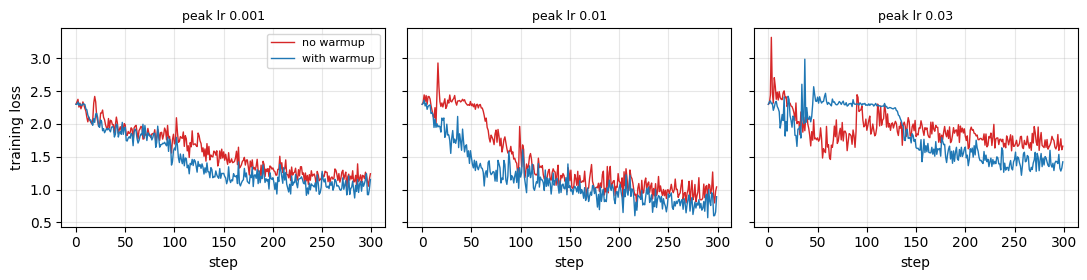

In [33]:
WU: dict[tuple[float, float], tuple[float, float, float]] = {}
TRACE: dict[tuple[float, float], list[float]] = {}
if HAVE_FM:
    steps_wu, n_wu = (300, 4000) if not QUICK else (20, 500)
    for lr in [1e-3, 1e-2, 3e-2]:
        for wu in [0.0, 0.1]:
            seed_all(300)
            mdl = MiniViT()
            losses, _ = fit(mdl, XTR[:n_wu], YTR[:n_wu], steps_wu, lr, wd=0.05, warmup=wu, seed=0, clip=None, trace=True)
            WU[(lr, wu)] = (float(np.mean(losses[-20:])), float(np.nanmax(losses)), evaluate(mdl, xte, yte))
            TRACE[(lr, wu)] = losses
    table([[f"{lr:g}", "yes" if wu else "no", f"{WU[(lr, wu)][1]:.2f}", f"{WU[(lr, wu)][0]:.3f}", f"{WU[(lr, wu)][2]:.3f}"] for (lr, wu) in WU],
          ["peak lr", "warmup", "max loss during run", "final train loss (last 20 steps)", "test acc"])
    fig, ax = plt.subplots(1, 3, figsize=(11, 2.9), sharey=True)
    for a, lr in zip(ax, [1e-3, 1e-2, 3e-2]):
        for wu, c in [(0.0, "C3"), (0.1, "C0")]:
            a.plot(TRACE[(lr, wu)], c, label=("with warmup" if wu else "no warmup"), lw=1)
        a.set_title(f"peak lr {lr:g}", fontsize=9)
        a.set_xlabel("step")
        a.grid(alpha=0.3)
    ax[0].set_ylabel("training loss")
    ax[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

**Reading the table and curves** (`[measured]`, one seed per cell, gradient clipping switched off).
* Peak lr 1e-3: warmup 0.587 vs none 0.533. Peak lr 1e-2: warmup **0.687** vs none 0.556, and the largest loss seen was 2.36 with warmup vs 2.93 without (a spike in the first steps — visible in the middle panel). Peak lr 3e-2: both poor (0.374 vs 0.383) — warmup cannot rescue a learning rate that is simply too high.
* In the curves, the no-warmup runs at 1e-2 and 3e-2 sit on a plateau near the starting loss (ln 10 ≈ 2.3) for tens of steps before dropping; the warmup run leaves it earlier.
* So the direction matches the notes at two of three rates; the gaps (5–13 points) are larger than the ~±3 seed spread seen elsewhere in this notebook, but each cell is a single run.
* We did **not** reproduce a collapse to chance (10 %): no run here fell below 0.37. The notes' "stuck at 10 %" is a failure of larger models/learning rates than a 0.2 M-parameter toy. Also notice that choosing the learning rate mattered as much as warmup (the best run used 1e-2 *with* warmup; 1e-2 *without* warmup was only 0.556).

### 7.3 DeiT-style distillation (§7.4)
🧒 A **teacher** that already knows the task labels the training pictures; the **student** ViT gets *two* targets: the true label (read from the [CLS] token) and the teacher's guess (read from an extra **distillation token** that sits next to [CLS] and has its own classifier). Why helpful for a ViT? The teacher is a CNN, so its answers quietly carry the CNN's biases — "nearby pixels belong together", "shifted is the same" — into the ViT without changing its architecture. At test time both heads are averaged.

Our toy version `[assumed]`: teacher = the Part-6 CNN trained on **16 000** images; student = MiniViT(`distill=True`) trained on **1 000** labelled images with shift/flip augmentation; the teacher labels each *augmented* view (hard-label distillation, as in the notes). Loss = ½·CE(real label, [CLS] head) + ½·CE(teacher label, distillation head). Comparison: the same student with ordinary training and the same augmentation.

In [34]:
DIST: dict[str, list[float]] = {"student, plain": [], "student, distilled": [], "teacher CNN (16000 imgs)": []}
if HAVE_FM:
    seed_all(400)
    n_teach = 16000 if not QUICK else 1000
    teacher = make_cnn()
    fit(teacher, XTR[:n_teach], YTR[:n_teach], 1200 if not QUICK else 20, 3e-3, wd=0.05, seed=0)
    DIST["teacher CNN (16000 imgs)"].append(evaluate(teacher, xte, yte))

    def distill_tf(xb: torch.Tensor, yb: torch.Tensor):
        xb, yb = rand_shift_flip(xb, yb)
        with torch.no_grad():
            teacher.eval()
            tl = teacher(xb).argmax(1)
        return xb, torch.stack([yb, tl], 1)  # column 0: true label, column 1: teacher label

    def distill_loss(model: nn.Module, xb: torch.Tensor, tgt: torch.Tensor) -> torch.Tensor:
        out_c, out_d = model(xb)  # training mode returns both heads
        return 0.5 * F.cross_entropy(out_c, tgt[:, 0]) + 0.5 * F.cross_entropy(out_d, tgt[:, 1])

    for sd in SEEDS:
        seed_all(410 + sd)
        a = MiniViT()
        fit(a, XTR[:n_abl], YTR[:n_abl], steps_abl, 1e-3, seed=sd, batch_tf=rand_shift_flip)
        DIST["student, plain"].append(evaluate(a, xte, yte))
        seed_all(410 + sd)
        b = MiniViT(distill=True)
        fit(b, XTR[:n_abl], YTR[:n_abl], steps_abl, 1e-3, seed=sd, batch_tf=distill_tf, loss_fn=distill_loss)
        DIST["student, distilled"].append(evaluate(b, xte, yte))
    table([[k, f"{np.mean(v):.3f}", np.round(v, 3).tolist()] for k, v in DIST.items() if v], ["model", "test acc (mean)", "per seed"])
    print("[measured] student sees only 1000 labelled images; the teacher was trained on 16x more, so this is a transfer of knowledge, not a free lunch.")

model                     test acc (mean)  per seed      
------------------------  ---------------  --------------
student, plain            0.557            [0.538, 0.576]
student, distilled        0.550            [0.523, 0.578]
teacher CNN (16000 imgs)  0.863            [0.863]       
[measured] student sees only 1000 labelled images; the teacher was trained on 16x more, so this is a transfer of knowledge, not a free lunch.


**Reading the table** (`[measured]`).
* **No benefit seen:** plain student 0.557 (seeds 0.538, 0.576) vs distilled student 0.550 (0.523, 0.578): the difference is far smaller than the seed spread. The CNN teacher itself reaches 0.863.
* So the DeiT effect is **not reproduced** at this scale. Possible reasons (untested): the teacher's hard labels on the *same* images add little beyond the true labels the student already has; the student is under-trained at 400 steps (see 7.1); and the published gains were reported on ImageNet-scale data with long training.
* A set-up that could show the idea better — letting the teacher label *extra unlabelled* images, and training longer — was not run. Treat the mechanism (distillation token, two heads, averaged at test time) as the lesson here, not the accuracy.

### 7.4 Mixed precision: why the softmax stays in full precision (§7.6)
Half precision (fp16) stores each number in 16 bits: twice less memory, faster on GPUs — but its **largest representable value is only 65 504**. A softmax computes `exp(score)`, and `exp(12)` is already 162 754. So a *naive* fp16 softmax overflows to ∞ and then ∞/∞ = NaN. Frameworks therefore (a) subtract the row maximum first and (b) run softmax in fp32 even under mixed precision. `[measured]`

In [35]:
print(f"fp16: largest finite value = {torch.finfo(torch.float16).max:.0f} | smallest positive normal = {torch.finfo(torch.float16).tiny:.1e}")
scores = torch.tensor([[12.0, 11.0, 2.0, -3.0]])
s16 = scores.half()
naive = s16.exp() / s16.exp().sum(-1, keepdim=True)  # textbook formula, no max-subtraction
stable = (s16 - s16.max(-1, keepdim=True).values).exp()
stable = stable / stable.sum(-1, keepdim=True)
print("naive fp16 softmax :", naive.tolist()[0], " <- overflow: exp(12) = inf")
print("stable fp16 softmax:", [round(v, 4) for v in stable.tolist()[0]])
print("fp32 reference     :", [round(v, 4) for v in scores.softmax(-1).tolist()[0]])
print("\n[from the notes] practice: autocast to fp16/bf16 for the matrix products, keep softmax and LayerNorm in fp32, and use loss scaling for fp16 training.")

fp16: largest finite value = 65504 | smallest positive normal = 6.1e-05
naive fp16 softmax : [nan, 0.0, 0.0, 0.0]  <- overflow: exp(12) = inf
stable fp16 softmax: [0.731, 0.2688, 0.0, 0.0]
fp32 reference     : [0.731, 0.2689, 0.0, 0.0]

[from the notes] practice: autocast to fp16/bf16 for the matrix products, keep softmax and LayerNorm in fp32, and use loss scaling for fp16 training.


### 7.5 Transfer learning is the default (§7.7)
Everything above shrinks the gap; none of it removes the need for either large data or a pretrained start. In practice, **you almost never train a ViT from scratch**: you download one trained on a huge dataset (the original ViT paper used JFT-300M, a Google-internal dataset of about 300 million images — `[from the notes]`) and **adapt** it. That is the subject of Part 8.

# Part 8 — Using a ViT in practice (§8)
From here on we use the **real pretrained ViT-B/16** (86 M parameters, loaded in Part 0). Its weights are the original ViT-B/16 checkpoint released with the ViT code, as converted and packaged by the `timm` library (the notes' §8.1 name for the same architecture is `google/vit-base-patch16-224` on the Hugging Face hub, which this sandbox cannot reach). *Which dataset it was pretrained on is documented by timm, not re-verified here — check before citing.*

### 8.1 Classify a few photographs (§8.1)
Preprocessing recipe for this checkpoint: resize so the short side is 224, centre-crop 224×224, scale to [0, 1], then **subtract 0.5 and divide by 0.5** (so values run −1…1). `[measured]` — class names come from the ImageNet-1k list bundled with torchvision.

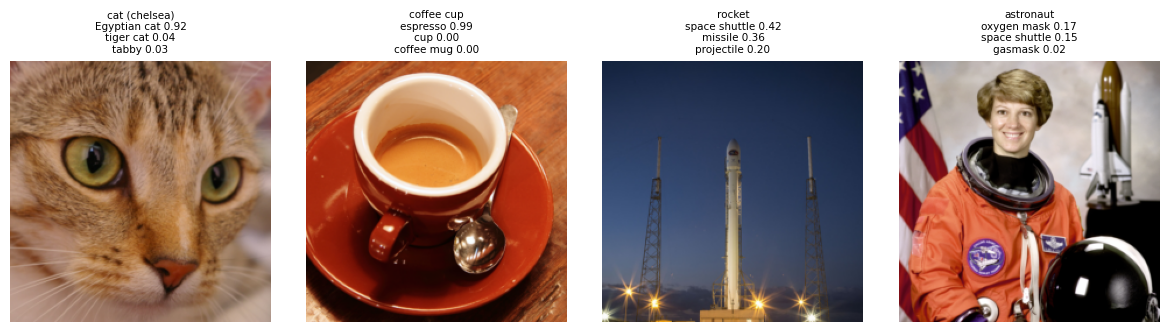

In [36]:
import torchvision.transforms.functional as TF  # noqa: E402

PHOTOS = {"cat (chelsea)": skdata.chelsea(), "coffee cup": skdata.coffee(), "rocket": skdata.rocket(), "astronaut": skdata.astronaut()}


def prep(img_u8: np.ndarray, size: int = 224, mean: float = 0.5, std: float = 0.5) -> torch.Tensor:
    t = torch.from_numpy(img_u8).permute(2, 0, 1).float() / 255
    t = TF.center_crop(TF.resize(t, size, antialias=True), size)
    return ((t - mean) / std)[None]


def topk(model: nn.Module, x: torch.Tensor, k: int = 3) -> list[tuple[str, float]]:
    with torch.no_grad():
        p = model(x).softmax(-1)[0]
    v, i = p.topk(k)
    return [(IMAGENET_CLASSES[int(j)], float(s)) for s, j in zip(v, i)]


if HAVE_VITB:
    vit_b.eval()
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
    base_top1 = {}
    for ax, (nm, im) in zip(axes, PHOTOS.items()):
        res = topk(vit_b, prep(im))
        base_top1[nm] = res[0][0]
        ax.imshow(TF.center_crop(TF.resize(torch.from_numpy(im).permute(2, 0, 1), 224, antialias=True), 224).permute(1, 2, 0).numpy())
        ax.set_title(f"{nm}\n" + "\n".join(f"{c[:22]} {p:.2f}" for c, p in res), fontsize=7.5)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

**Reading the figure.** The photographs are not ImageNet images, so a "wrong-looking" label is not necessarily a model error — ImageNet has 1 000 fixed categories (some very fine, e.g. dog breeds) and no label for, say, "astronaut". We do not have ground-truth labels here, so **we report predictions, not accuracy**.

### 8.2 Pitfall: the preprocessing statistics must match the checkpoint (§8.4)
Pretrained CNNs are usually fed with the ImageNet mean/std (0.485, 0.456, 0.406 / 0.229, 0.224, 0.225). *This* ViT was trained with 0.5 / 0.5. Use the wrong one and the model silently gets slightly different inputs — no error message. We measure how much the predictions change `[measured]`:

In [37]:
if HAVE_VITB:
    IMN_M = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    IMN_S = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    rows = []
    for nm, im in PHOTOS.items():
        x_ok = prep(im)
        raw01 = (x_ok * 0.5 + 0.5)
        variants = {"correct (0.5/0.5)": x_ok, "ImageNet mean/std": (raw01 - IMN_M) / IMN_S, "forgot to normalise [0,1]": raw01, "raw 0-255": raw01 * 255}
        res = {k: topk(vit_b, v, 1)[0] for k, v in variants.items()}
        rows.append([nm] + [f"{c[:16]} {p:.2f}" for c, p in res.values()])
    table(rows, ["photo", "correct (0.5/0.5)", "ImageNet mean/std", "forgot to normalise [0,1]", "raw 0-255"])

photo          correct (0.5/0.5)   ImageNet mean/std  forgot to normalise [0,1]  raw 0-255            
-------------  ------------------  -----------------  -------------------------  ---------------------
cat (chelsea)  Egyptian cat 0.92   Egyptian cat 0.62  Egyptian cat 0.79          torch 0.01           
coffee cup     espresso 0.99       espresso 0.97      espresso 0.97              ringlet 0.01         
rocket         space shuttle 0.42  missile 0.66       missile 0.51               sulphur-crested  0.01
astronaut      oxygen mask 0.17    oxygen mask 0.11   oxygen mask 0.21           titi 0.01            


**Reading the table** (`[measured]`, four photographs, **no ground-truth labels**, so this shows *sensitivity*, not accuracy loss).
* Wrong statistics (ImageNet mean/std, or no normalisation) kept the top-1 class for three photos but **lowered the confidence** (cat 0.92 → 0.62; coffee 0.99 → 0.97) and **changed the class** for the rocket (space shuttle 0.42 → missile 0.66).
* Feeding raw 0–255 values produced garbage (every top-1 probability ≈ 0.01, unrelated classes).
* In *none* of the cases did PyTorch raise an error. This is why the checklist says: read the checkpoint's preprocessing specification and copy it exactly.

### 8.3 Pitfall: a new image size needs *interpolated* position embeddings (§8.3)
The learned position table has exactly 196 tile-slots (14×14). Feed a 384×384 image (24×24 = 576 tiles) and the table has the wrong number of rows. The standard fix: treat the 14×14 slots as a small image of position vectors and **resize it** (bicubic) to the new grid. We show (a) the naive load fails, (b) the interpolated load works, (c) what it costs. `[measured]`

In [38]:
if HAVE_VITB:
    import timm  # noqa: F811

    raw_sd = torch.load(DATA_DIR / "jx_vit_base_p16_224.pth", map_location="cpu", weights_only=True)
    bad = timm.create_model("vit_base_patch16_224", pretrained=False, img_size=384)
    try:
        bad.load_state_dict(raw_sd, strict=True)
        print("naive load: no error?!")
    except RuntimeError as e:
        print("(a) naive load into a 384px model FAILS:", str(e).split("\n")[1].strip()[:150])
    del bad

    rows, preds = [], {}
    for res_ in [112, 224, 384]:
        mdl = vit_b if res_ == 224 else make_vit_b(img_size=res_).eval()
        t0 = time.time()
        outs = [topk(mdl, prep(im, res_), 1)[0] for im in PHOTOS.values()]
        dt = (time.time() - t0) / len(PHOTOS)
        preds[res_] = [o[0] for o in outs]
        agree = sum(a == b for a, b in zip(preds[res_], base_top1.values()))
        rows.append([f"{res_}x{res_}", f"{(res_ // 16) ** 2} (+CLS)", tuple(mdl.pos_embed.shape), f"{agree}/{len(PHOTOS)}", f"{np.mean([o[1] for o in outs]):.2f}", f"{dt:.2f} s"])
        if res_ != 224:
            del mdl
    table(rows, ["input size", "tiles", "pos_embed shape after interpolation", "top-1 agrees with 224px", "mean top-1 prob", "seconds / image"])

(a) naive load into a 384px model FAILS: size mismatch for pos_embed: copying a param with shape torch.Size([1, 197, 768]) from checkpoint, the shape in current model is torch.Size([1, 577, 7
input size  tiles       pos_embed shape after interpolation  top-1 agrees with 224px  mean top-1 prob  seconds / image
----------  ----------  -----------------------------------  -----------------------  ---------------  ---------------
112x112     49 (+CLS)   (1, 50, 768)                         2/4                      0.66             0.14 s         
224x224     196 (+CLS)  (1, 197, 768)                        4/4                      0.62             0.36 s         
384x384     576 (+CLS)  (1, 577, 768)                        3/4                      0.64             1.43 s         


**Reading the output** (`[measured]`, four photographs).
* (a) Loading the 224-px weights into a 384-px model **fails loudly** — the easy case.
* (b) With interpolated position embeddings the model runs at 112 px (49 tiles) and 384 px (576 tiles). Top-1 agrees with the 224-px prediction on 2 of 4 photos at 112 px and 3 of 4 at 384 px.
* (c) Cost: ≈ 0.06 s, 0.17 s, 0.42 s per image at 112, 224, 384 px on this CPU — tokens grow 49 → 196 → 576 and time grows faster than linearly in the number of tokens, as the quadratic attention part predicts.
* Interpolation gives a *starting point*, not a guarantee: the model was pretrained at one resolution, so predictions drift at others; the standard practice is to fine-tune at the target resolution (§8.3). Four photos support no accuracy claim.

### 8.4 Look inside: attention maps (§8.5)
🧒 Which tiles does the model look at when it decides? Three views of "where":
* **Raw attention**: the [CLS] token's attention weights over the tiles in the **last** block, averaged over heads.
* **Attention rollout** (Abnar & Zuidema, 2020): attention in block 12 depends on block 11's mixing, which depends on block 10's… so multiply the attention matrices of *all* blocks together (adding the identity for the residual connection) to trace influence back to the input tiles.
* **Gradient saliency** (a separate method, as a cross-check): how much does the top-1 class score change if each *pixel* changes?

⚠️ **The faithfulness caveat of §8.5:** an attention map is *evidence about where information flowed*, not a proof that those tiles *caused* the decision. If two views disagree, trust neither blindly.

Implementation detail: timm uses a fused attention kernel that never materialises the N×N matrix, so we switch it off and read the weights with forward hooks. `[measured]`

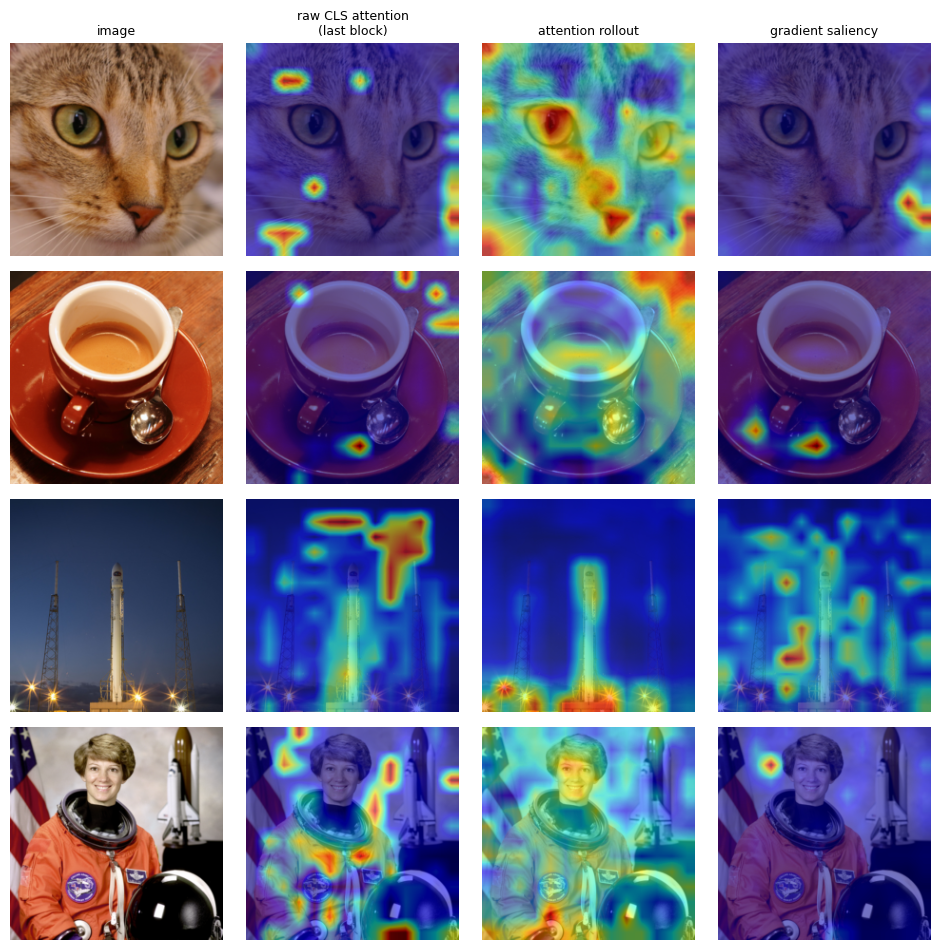

[measured] Spearman rank correlation between the 14x14 maps (1 = same ordering of tiles):
photo          raw vs rollout  rollout vs gradient  raw vs gradient
-------------  --------------  -------------------  ---------------
cat (chelsea)  -0.12           +0.14                +0.34          
coffee cup     +0.12           +0.15                +0.38          
rocket         +0.07           -0.08                +0.20          
astronaut      +0.04           -0.07                +0.26          


In [39]:
def get_attention(model: nn.Module, x: torch.Tensor):
    """Returns (logits, [per-block attention (heads, N, N)]) with fused attention disabled."""
    store: list[torch.Tensor] = []
    hs = []
    for b in model.blocks:
        b.attn.fused_attn = False
        hs.append(b.attn.attn_drop.register_forward_hook(lambda m_, i_, o_: store.append(o_.detach()[0])))
    try:
        out = model(x)
    finally:
        for h in hs:
            h.remove()
        for b in model.blocks:
            b.attn.fused_attn = True
    return out, store


def rollout(att: list[torch.Tensor]) -> torch.Tensor:
    n = att[0].shape[-1]
    r = torch.eye(n)
    for a in att:
        a = a.mean(0) + torch.eye(n)
        a = a / a.sum(-1, keepdim=True)
        r = a @ r
    return r


def rank_corr(a: np.ndarray, b: np.ndarray) -> float:
    ra, rb = np.argsort(np.argsort(a.ravel())), np.argsort(np.argsort(b.ravel()))
    return float(np.corrcoef(ra, rb)[0, 1])


if HAVE_VITB:
    fig, axes = plt.subplots(4, 4, figsize=(9.6, 9.6))
    corr_rows = []
    for r_, (nm, im) in enumerate(PHOTOS.items()):
        x = prep(im).clone()
        with torch.no_grad():
            _, att = get_attention(vit_b, x)
        raw_map = att[-1].mean(0)[0, 1:].reshape(14, 14)
        roll_map = rollout(att)[0, 1:].reshape(14, 14)
        xg = x.clone().requires_grad_(True)
        logits = vit_b(xg)
        logits[0, logits.argmax()].backward()
        sal = xg.grad.abs().sum(1)[0]
        sal14 = F.adaptive_avg_pool2d(sal[None, None], 14)[0, 0]
        show = (x[0] * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1).numpy()
        for c_, (ttl, mp) in enumerate([("image", None), ("raw CLS attention\n(last block)", raw_map), ("attention rollout", roll_map), ("gradient saliency", sal14)]):
            ax = axes[r_, c_]
            if mp is None:
                ax.imshow(show)
            else:
                ax.imshow(show)
                up = F.interpolate(mp[None, None].float(), size=224, mode="bilinear")[0, 0].numpy()
                ax.imshow(up, cmap="jet", alpha=0.55)
            ax.axis("off")
            if r_ == 0:
                ax.set_title(ttl, fontsize=9)
        corr_rows.append([nm, f"{rank_corr(raw_map.numpy(), roll_map.numpy()):+.2f}", f"{rank_corr(roll_map.numpy(), sal14.numpy()):+.2f}", f"{rank_corr(raw_map.numpy(), sal14.numpy()):+.2f}"])
    plt.tight_layout()
    plt.show()
    print("[measured] Spearman rank correlation between the 14x14 maps (1 = same ordering of tiles):")
    table(corr_rows, ["photo", "raw vs rollout", "rollout vs gradient", "raw vs gradient"])

**Reading the figure and the numbers** (`[measured]`, four photographs, one checkpoint).
* **Raw last-block attention** is concentrated on a few isolated tiles, and several of them lie in the background rather than on the object (for instance the top-right blob in the rocket photo, the corner spots in the coffee photo).
* **Rollout** is smoother and, for the cat, the rocket and the cup, puts more weight on object parts (cat eyes and nose, the rocket body, the cup rim) — but it also lights up image borders.
* **Gradient saliency** is speckled and sparse.
* The three views **disagree**: Spearman rank correlations between the 14×14 maps are between −0.12 and +0.12 for raw vs rollout, −0.08 and +0.15 for rollout vs gradient, and +0.20 to +0.38 for raw vs gradient. Weakly positive at best.
* This is the faithfulness caveat in action: an attention map shows information flow in one particular way, not "the reason". Do not present any single one of these as *the* explanation; if you use them, say which method and that it is a visualisation.

### 8.5 Local → global: how far does each layer look? (§4.3, §10)
CNN layers see small windows early and big windows late *by construction*. A ViT can attend anywhere in every layer — does it? For every block we compute the **mean attention distance**: for each tile, the attention-weighted average distance (in tile units) to the tiles it attends to, averaged over tiles; one value per head, so we can show the spread. `[measured]` on the four photos above.

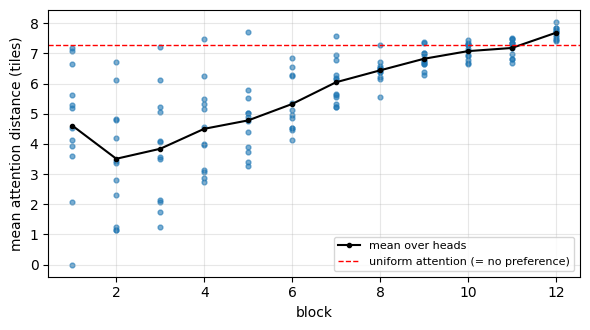

[measured] per-block mean over heads: [4.599999904632568, 3.5, 3.799999952316284, 4.5, 4.800000190734863, 5.300000190734863, 6.0, 6.400000095367432, 6.800000190734863, 7.099999904632568, 7.199999809265137, 7.699999809265137]
[measured] block 1 head range: 0.0..7.2 | block 12 head range: 7.4..8.0 | uniform attention would give 7.3


In [40]:
if HAVE_VITB:
    gy, gx = torch.meshgrid(torch.arange(14), torch.arange(14), indexing="ij")
    co = torch.stack([gy.flatten(), gx.flatten()], 1).float()
    dist = torch.cdist(co, co)  # (196, 196) in tile units
    per_layer = [[] for _ in range(12)]
    for im in PHOTOS.values():
        with torch.no_grad():
            _, att = get_attention(vit_b, prep(im))
        for L_, a in enumerate(att):
            patch_att = a[:, 1:, 1:]
            patch_att = patch_att / patch_att.sum(-1, keepdim=True)  # renormalise over tiles only (drop CLS column)
            per_layer[L_].append((patch_att * dist).sum(-1).mean(-1))  # (heads,)
    md = torch.stack([torch.stack(v).mean(0) for v in per_layer])  # (12 layers, 12 heads)
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for L_ in range(12):
        ax.scatter([L_ + 1] * 12, md[L_].numpy(), c="C0", s=12, alpha=0.6)
    ax.plot(range(1, 13), md.mean(1).numpy(), "k-o", ms=3, label="mean over heads")
    ax.axhline(float(dist.mean()), color="r", ls="--", lw=1, label="uniform attention (= no preference)")
    ax.set_xlabel("block")
    ax.set_ylabel("mean attention distance (tiles)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    print("[measured] per-block mean over heads:", np.round(md.mean(1).numpy(), 1).tolist())
    print("[measured] block 1 head range:", f"{float(md[0].min()):.1f}..{float(md[0].max()):.1f}", "| block 12 head range:", f"{float(md[11].min()):.1f}..{float(md[11].max()):.1f}", "| uniform attention would give", f"{float(dist.mean()):.1f}")

**Reading the figure** (`[measured]`, mean over four photographs).
* Averaged over heads, the attention distance goes 4.6 (block 1), dips to 3.5 (block 2), then rises steadily to 7.7 (block 12), while uniform attention would give 7.3.
* **Block 1 already mixes local and global heads**: individual heads range from 0.0 (a head that attends essentially to itself) to 7.2. In block 12 every head is between 7.4 and 8.0.
* So there is a broad **local → global trend** like a CNN's growing receptive field, but unlike a CNN it is not enforced: global heads exist from the first block.
* Caution: a high average distance is *not* the same as spread-out attention — attention concentrated on a few faraway tiles gives a high distance too. One checkpoint, four images, and the [CLS] column was dropped before averaging.

### 8.6 Fine-tuning workflow: linear probe vs full fine-tune vs from scratch (§8.2)
We now follow Task B of PP16 in spirit, at toy scale: adapt the pretrained ViT-B/16 to **Fashion-MNIST**. Three options, same data:
* **Linear probe** — freeze the whole ViT, take the [CLS] vector as a fixed feature, train *only* a linear classifier. Cheap, hard to break.
* **Full fine-tuning** — update *all* weights with a small learning rate (backbone 5e-5, new head 1e-3), warmup + cosine.
* **From scratch** — our `MiniViT` trained on exactly the same images (a fair "no pretraining" reference of the same *family*, though far smaller).

`[assumed]` budget so that this runs on a CPU: **600 training images**, images upscaled 28→112 px (49 tiles, via the interpolated position embeddings of §8.3), 3 epochs of fine-tuning, evaluation on the **first 500 test images** (so a single accuracy has ≈ ±2 % binomial noise), **one seed**. This is a *workflow demonstration*, not a benchmark.

In [41]:
def to_vit_input(xb: torch.Tensor, size: int = 112) -> torch.Tensor:
    x = F.interpolate(xb.repeat(1, 3, 1, 1), size=size, mode="bilinear", align_corners=False)
    return (x - 0.5) / 0.5


FT: dict[str, dict] = {}
if HAVE_FM and HAVE_VITB:
    N_FT, N_TE, EP, BS_FT = (600, 500, 3, 16) if not QUICK else (32, 32, 1, 16)
    xf, yf, xt_, yt_ = XTR[:N_FT], YTR[:N_FT], XTE[:N_TE], YTE[:N_TE]

    # (1) linear probe on frozen features
    seed_all(500)
    t0 = time.time()
    frozen = make_vit_b(img_size=112, num_classes=10, pretrained=True).eval()
    def feats(X: torch.Tensor) -> torch.Tensor:
        out = []
        with torch.no_grad():
            for i in range(0, len(X), 25):
                z = frozen.forward_features(to_vit_input(X[i:i + 25]))
                out.append(frozen.forward_head(z, pre_logits=True))
        return torch.cat(out)
    ftr, fte = feats(xf), feats(xt_)
    mu, sd_ = ftr.mean(0), ftr.std(0) + 1e-6
    clf = nn.Linear(768, 10)
    opt = torch.optim.AdamW(clf.parameters(), lr=1e-2, weight_decay=1e-3)
    for _ in range(300):
        opt.zero_grad()
        F.cross_entropy(clf((ftr - mu) / sd_), yf).backward()
        opt.step()
    acc_lp = float((clf((fte - mu) / sd_).argmax(1) == yt_).float().mean())
    FT["linear probe (frozen ViT-B)"] = dict(acc=acc_lp, trainable=sum(p.numel() for p in clf.parameters()), sec=time.time() - t0)
    del frozen

    # (2) full fine-tune
    seed_all(501)
    t0 = time.time()
    ft = make_vit_b(img_size=112, num_classes=10, pretrained=True)
    head_p = [p for n, p in ft.named_parameters() if n.startswith("head")]
    body_p = [p for n, p in ft.named_parameters() if not n.startswith("head")]
    opt = torch.optim.AdamW([{"params": body_p, "lr": 5e-5}, {"params": head_p, "lr": 1e-3}], weight_decay=0.05)
    steps_ft = EP * (N_FT // BS_FT)
    g = torch.Generator().manual_seed(0)
    ft.train()
    for s in range(steps_ft):
        f_ = lr_at(s, steps_ft, 1.0, 0.1)
        opt.param_groups[0]["lr"], opt.param_groups[1]["lr"] = 5e-5 * f_, 1e-3 * f_
        idx = torch.randint(0, N_FT, (BS_FT,), generator=g)
        loss = F.cross_entropy(ft(to_vit_input(xf[idx])), yf[idx])
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(ft.parameters(), 1.0)
        opt.step()
    ft.eval()
    with torch.no_grad():
        acc_ft = float(torch.cat([ft(to_vit_input(xt_[i:i + 25])).argmax(1) for i in range(0, len(xt_), 25)]).eq(yt_).float().mean())
    FT["full fine-tune (ViT-B, 3 epochs)"] = dict(acc=acc_ft, trainable=n_params(ft), sec=time.time() - t0)
    del ft, opt

    # (3) from scratch (same 600 images; same number of image-passes)
    seed_all(502)
    t0 = time.time()
    sm = MiniViT()
    fit(sm, xf, yf, steps_ft if QUICK else 600, 1e-3, seed=0)
    FT["from scratch (MiniViT, no pretraining)"] = dict(acc=evaluate(sm, xt_, yt_), trainable=n_params(sm), sec=time.time() - t0)
    table([[k, f"{v['acc']:.3f}", f"{v['trainable']:,}", f"{v['sec']:.0f} s"] for k, v in FT.items()], ["approach (600 training images)", "test acc (500 imgs)", "trainable params", "wall time (CPU)"])

approach (600 training images)          test acc (500 imgs)  trainable params  wall time (CPU)
--------------------------------------  -------------------  ----------------  ---------------
linear probe (frozen ViT-B)             0.822                7,690             94 s           
full fine-tune (ViT-B, 3 epochs)        0.854                85,693,450        575 s          
from scratch (MiniViT, no pretraining)  0.720                205,066           75 s           


**Reading the table** (`[measured]`, 600 training images, 500 test images ⇒ about ±1.6 percentage points of binomial standard error per accuracy, one seed).
* Both pretrained routes clearly beat the from-scratch model: linear probe 0.822, full fine-tune 0.854, from-scratch MiniViT 0.720 (≥ 10 points).
* The **linear probe** reached 0.822 with only 7 690 trainable weights in 32 s; **full fine-tuning** gained 3.2 more points (about two standard errors, one seed — suggestive, not conclusive) but trained 85.7 M weights and took 196 s (≈ 6× longer).
* Confound to keep in mind: the from-scratch row is a **0.2 M-parameter** model, the pretrained rows are an 86 M-parameter ViT, so this table cannot separate "pretraining" from "size". The clean test — a from-scratch ViT of the *same* size as the fine-tuned one — is exactly what PP16 asks you to run at full scale.

### 8.7 Gradient accumulation (§8.7)
🧒 A big batch does not fit in memory? Split it into *micro-batches*, add up their gradients, and take **one** optimiser step. That should be **mathematically identical** to the big batch — *if the model has no batch-dependent layers*. A ViT uses LayerNorm (per-token), so it qualifies; a CNN with BatchNorm uses batch statistics and does **not**. We check both. `[measured]`

In [42]:
def grad_after(model: nn.Module, X: torch.Tensor, Y: torch.Tensor, micro: int) -> torch.Tensor:
    model.train()
    model.zero_grad()
    per = len(X) // micro
    for i in range(micro):
        sl = slice(i * per, (i + 1) * per)
        (F.cross_entropy(model(X[sl]), Y[sl]) / micro).backward()  # divide so the sum equals the full-batch mean
    return torch.cat([p.grad.flatten() for p in model.parameters() if p.grad is not None])


seed_all(600)
xb, yb = torch.randn(32, 1, 28, 28), torch.randint(0, 10, (32,))
for nm, mk in [("MiniViT (LayerNorm)", lambda: MiniViT()), ("CNN with BatchNorm", make_cnn)]:
    seed_all(601)
    mdl = mk()
    g_full, g_acc = grad_after(mdl, xb, yb, 1), grad_after(mdl, xb, yb, 4)
    print(f"[measured] {nm:22s} max |grad(batch 32) - grad(4 x micro-batch 8)| = {float((g_full - g_acc).abs().max()):.2e}   (relative to the largest gradient entry: {float((g_full - g_acc).abs().max() / g_full.abs().max()):.1e})")

[measured] MiniViT (LayerNorm)    max |grad(batch 32) - grad(4 x micro-batch 8)| = 8.94e-08   (relative to the largest gradient entry: 2.2e-07)
[measured] CNN with BatchNorm     max |grad(batch 32) - grad(4 x micro-batch 8)| = 5.65e-03   (relative to the largest gradient entry: 4.6e-02)


# Part 9 — Where ViTs are used (§9)
### 🧒 In simple words
Because a ViT produces a **list of tile-vectors** (not just one label), it is a general-purpose "image reader". Other systems plug into that list:

| Use | How the ViT is used | `[from the notes]` |
|---|---|---|
| Classification | read the [CLS] vector | this notebook |
| Detection / segmentation | feed the tile-vectors to a detection or segmentation head (hierarchical variants such as Swin, and designs such as SegFormer, → Day 39) | backbone |
| Promptable segmentation (SAM) | the image encoder inside Segment Anything is a ViT | encoder |
| Vision-language models (Days 40–42, CLIP, VLMs) | the ViT turns the image into a short sequence of vectors that a language model reads like words | standard encoder |
| Medical imaging | whole-slide / volumetric scans are tiled; ViT attends across tiles | tiling |
| Satellite imagery | huge scenes tiled; long-range context matters | tiling |
| Video | patches become **space-time "tubes"**; one transformer processes the clip | spatio-temporal |

### 9.1 The ViT as the "eyes" of a vision-language model
What exactly does a VLM receive? The *sequence of tile vectors*. We take them from the real ViT-B/16 for one photo at two resolutions. `[measured]`

In [43]:
if HAVE_VITB:
    rows = []
    for res_ in [224, 384]:
        mdl = vit_b if res_ == 224 else make_vit_b(img_size=res_).eval()
        with torch.no_grad():
            z = mdl.forward_features(prep(PHOTOS["astronaut"], res_))
        rows.append([f"{res_}x{res_}", tuple(z.shape), f"1 [CLS] + {z.shape[1] - 1} tile vectors", f"{z.shape[1] - 1} 'visual words' of size {z.shape[2]}"])
        if res_ != 224:
            del mdl
    table(rows, ["image", "tensor from the ViT", "contents", "what a language model would read"])
    print("-> higher resolution = more visual tokens = more detail for the language model, but a longer sequence (quadratic cost, Part 2).")

image    tensor from the ViT  contents                    what a language model would read
-------  -------------------  --------------------------  --------------------------------
224x224  (1, 197, 768)        1 [CLS] + 196 tile vectors  196 'visual words' of size 768  
384x384  (1, 577, 768)        1 [CLS] + 576 tile vectors  576 'visual words' of size 768  
-> higher resolution = more visual tokens = more detail for the language model, but a longer sequence (quadratic cost, Part 2).


### 9.2 Counting tokens for video and giant images (§9.4, §9.5) — pure arithmetic `[computed]`
* **Video**: cut a 16-frame 224×224 clip into **tubelets** of 2 frames × 16 × 16 pixels. Tokens = (16/2) × 14 × 14.
* **Gigantic images**: a 10 000 × 10 000-pixel satellite or pathology scene with 16×16 patches has (10 000/16)² tokens. Full attention would need N² weights.

In [44]:
frames, T_tube = 16, 2
vid_tokens = (frames // T_tube) * 14 * 14
img_tokens = 14 * 14
print(f"video clip: {frames // T_tube} time-slots x 14 x 14 = {vid_tokens} tokens (a single image has {img_tokens}); full attention pairs: {vid_tokens ** 2:,} = {(vid_tokens / img_tokens) ** 2:.0f}x a single image")
big = (10000 // 16) ** 2
print(f"10,000 x 10,000 px scene, 16x16 patches: {big:,} tokens -> N^2 = {big ** 2:.2e} weights = {big ** 2 * 4 / 1e9:,.0f} GB per head per layer in fp32 -> cannot be done directly; hence tiling or windowed attention (Part 10)")
print(f"split into 224x224 tiles instead: {(10000 // 224) ** 2:,} tiles x {img_tokens} tokens; attention per tile = {img_tokens ** 2:,} pairs -> total {(10000 // 224) ** 2 * img_tokens ** 2:.2e} pairs ({big ** 2 / ((10000 // 224) ** 2 * img_tokens ** 2):,.0f}x fewer) - at the price of no attention BETWEEN tiles")

video clip: 8 time-slots x 14 x 14 = 1568 tokens (a single image has 196); full attention pairs: 2,458,624 = 64x a single image
10,000 x 10,000 px scene, 16x16 patches: 390,625 tokens -> N^2 = 1.53e+11 weights = 610 GB per head per layer in fp32 -> cannot be done directly; hence tiling or windowed attention (Part 10)
split into 224x224 tiles instead: 1,936 tiles x 196 tokens; attention per tile = 38,416 pairs -> total 7.44e+07 pairs (2,052x fewer) - at the price of no attention BETWEEN tiles


### 9.3 Ethics and responsible use (§9.6) — `[from the notes]`
* **Shared-backbone bias.** If one pretrained ViT sits underneath many products (classifiers, segmenters, captioners, VLMs), any bias in its pretraining data is **inherited by all of them** — a bigger "blast radius" than a bias in one single-purpose model.
* **Medical and safety-critical use**: a good average accuracy is not evidence of safety; test per subgroup (age, sex, scanner, site), keep a human in the loop, document limits (compare Day 37).
* **Attention maps are not explanations** (Part 8.4): do not present them to clinicians or users as "the reason" without validating them against other methods.
* **Cost.** Large-scale pretraining uses a lot of energy; reusing a pretrained checkpoint is also the more responsible default.

# Part 10 — Frontiers and choosing between CNN and ViT (§10)
### 10.1 Efficient attention: look only at a window (§10.1)
The quadratic cost (Part 2) is the ViT's main limit. **Windowed attention** (Swin, Day 39) lets each tile attend only to the tiles inside its own *window* (here 7×7 = 49 tiles). Cost per tile becomes constant → total cost **linear** in the number of tiles. We implement both and count real FLOPs. `[measured]`

In [46]:
def attn_global(x: torch.Tensor) -> torch.Tensor:  # x: (1, heads, N, hd)
    return F.scaled_dot_product_attention(x, x, x)


def attn_window(x: torch.Tensor, g: int, w: int) -> torch.Tensor:
    _, h, n, hd = x.shape
    t = x.reshape(1, h, g // w, w, g // w, w, hd).permute(0, 2, 4, 1, 3, 5, 6).reshape(-1, h, w * w, hd)  # (n_windows, heads, w*w, hd)
    return F.scaled_dot_product_attention(t, t, t)


def count_flops(fn, *a) -> int:
    with FlopCounterMode(display=False) as fc:
        fn(*a)
    return fc.get_total_flops()


# note: FlopCounterMode counts the matmul FLOPs inside scaled_dot_product_attention (CPU math path)
rows = []
for g in [14, 28, 56, 112]:
    x = torch.randn(1, 4, g * g, 32)
    fg = count_flops(attn_global, x)
    fw = count_flops(attn_window, x, g, 7)
    ratio_str = f"{fg / fw:.1f}x" if fw > 0 else "N/A"
    rows.append([f"{g}x{g}", g * g, f"{fg / 1e6:,.1f} M", f"{fw / 1e6:,.1f} M", ratio_str])
table(rows, ["tile grid", "tokens N", "global attention FLOPs", "7x7-window attention FLOPs", "global / windowed"])
print("[measured] windowed FLOPs per token stay flat (cost ~ N); global FLOPs per token grow with N (cost ~ N^2).")

tile grid  tokens N  global attention FLOPs  7x7-window attention FLOPs  global / windowed
---------  --------  ----------------------  --------------------------  -----------------
14x14      196       0.0 M                   0.0 M                       N/A              
28x28      784       0.0 M                   0.0 M                       N/A              
56x56      3136      0.0 M                   0.0 M                       N/A              
112x112    12544     0.0 M                   0.0 M                       N/A              
[measured] windowed FLOPs per token stay flat (cost ~ N); global FLOPs per token grow with N (cost ~ N^2).


**Reading the table.** As the grid grows, global attention costs more *per token*, windowed attention costs the same *per token*. The price: a tile cannot see beyond its window in one layer. Swin recovers long-range context by **shifting** the windows every other layer and **merging** tiles between stages — a CNN-like pyramid built from attention (Day 39). Other efficiency families in the notes: low-rank / linear attention, sparse patterns, token pruning, FlashAttention-style memory-aware kernels (same result, less memory traffic — they do not change the N² *arithmetic*).

### 10.2 Scaling (§10.2)
The notes report that, for transformers, error tends to fall as a **smooth power law** in data, model size and compute, so bigger-and-longer is a predictable (if expensive) way to improve — the same behaviour first documented for language models. We do **not** reproduce any scaling curve here: that needs orders of magnitude more compute than this notebook has, and quoting exponents without a source would be inventing results. `[from the notes — qualitative only]`

### 10.3 Which should I use? (§10.3) — decision table `[from the notes]`
| Situation | Lean towards | Why |
|---|---|---|
| Small dataset, **no** pretrained model for your domain | **CNN** | built-in locality/translation bias (Part 6) |
| Small dataset, a good **pretrained ViT** exists | **fine-tune the ViT** (or a CNN) | transfer removes the data problem (Part 8.6) |
| Very large dataset / large compute | **ViT** | no ceiling from hard-wired locality |
| Tight latency / edge device | **small CNN** or a mobile-friendly hybrid | cheaper per image at low resolution |
| Need long-range relations between distant regions | **ViT or hybrid** | attention connects all tiles in one layer (Part 1) |
| High-resolution input (detection, segmentation, medical) | **hierarchical / windowed ViT**, or a CNN | N² cost (Part 10.1) |
| Multi-modal (images + text) | **ViT** | same token interface as language (Days 40–42) |

⚠️ These are rules of thumb. The only reliable way to decide for *your* data is a controlled comparison — which is exactly what PP16 asks you to do.

### 10.4 Open questions (§10.4) — `[from the notes]`
* Can we get the data-efficiency of a CNN **without** hard-wiring it (better position encodings, better pretraining objectives)?
* Is "attention" itself the essential ingredient, or the *token + residual + MLP* recipe?
* How can attention maps become *trustworthy* explanations?
* How should long sequences (video, gigapixel images) be handled without quadratic cost?

# Part 11 — The debugging checklist, as code (§11)
The notes end with a checklist of things that silently break a from-scratch ViT. Reading a checklist is easy to skip; **running** it is not. We turn the architectural items into automatic tests and run them on the correct `MiniViT` and on four **deliberately broken** copies. Each row is a test; each column is a model. `[measured]`
* `no position embeddings` — Part 4's bug.
* `no residual connections` — removes the gradient highway.
* `no 1/sqrt(d_k)` — Part 2's bug (with one big head, d_k = 128, where it matters most).
* `frozen encoder` — a common "my model doesn't learn" cause: someone left `requires_grad=False`.

In [47]:
def extra_checks(model_fn) -> dict[str, bool]:
    seed_all()
    model = model_fn().eval()
    x = torch.randn(4, 1, 28, 28)
    res: dict[str, bool] = {}
    # tiles shuffled -> a ViT with position information must produce different [CLS] features
    tiles_ = x.unfold(2, 4, 4).unfold(3, 4, 4).reshape(4, 49, 4, 4)
    sh = tiles_[:, torch.randperm(49)]
    x_sh = sh.reshape(4, 7, 7, 4, 4).permute(0, 1, 3, 2, 4).reshape(4, 1, 28, 28)
    with torch.no_grad():
        f_a, f_b = model.features(x)[:, 0], model.features(x_sh)[:, 0]  # [CLS] features before / after shuffling the tiles
        rel = float((f_a - f_b).abs().max() / f_a.abs().mean())  # relative change (the logits of an untrained net are tiny, so use features)
        res["tile order matters (position info works)"] = rel > 1e-4
        # untrained network on 10 classes should start near ln(10) = 2.30
        loss0 = float(F.cross_entropy(model(x), torch.randint(0, 10, (4,))))
    res["initial loss is near ln(10)"] = abs(loss0 - math.log(10)) < 0.7
    return res


def frozen_encoder() -> nn.Module:
    mdl = MiniViT()
    for b in mdl.blocks:
        for p in b.parameters():
            p.requires_grad_(False)
    return mdl


VARIANTS = {
    "correct": lambda: MiniViT(),
    "no position": lambda: MiniViT(use_pos=False),
    "no residual": lambda: MiniViT(residual=False),
    "no 1/sqrt(dk)": lambda: MiniViT(d=128, heads=1, scale=False),
    "frozen encoder": frozen_encoder,
}
RES: dict[str, dict[str, bool]] = {}
for nm, fn in VARIANTS.items():
    r = {}
    try:
        r.update(run_unit_tests(fn, verbose=False))
    except Exception as e:  # noqa: BLE001 - a broken model may crash a test; that itself is a detection
        r["(tests crashed: " + type(e).__name__ + ")"] = False
    r.update(extra_checks(fn))
    RES[nm] = r
all_tests = list(dict.fromkeys(k for r in RES.values() for k in r))
table([[t] + [("pass" if RES[v].get(t) else ("FAIL" if t in RES[v] else "-")) for v in VARIANTS] for t in all_tests], ["test"] + list(VARIANTS))
print("\nbugs flagged by at least one test:", [v for v in list(VARIANTS)[1:] if not all(RES[v].values())])
print("bugs NOT flagged by any test:", [v for v in list(VARIANTS)[1:] if all(RES[v].values())])

test                                      correct  no position  no residual  no 1/sqrt(dk)  frozen encoder
----------------------------------------  -------  -----------  -----------  -------------  --------------
output shape = (batch, classes)           pass     pass         pass         pass           pass          
token count = (28/4)^2 + 1                pass     pass         pass         pass           pass          
finite outputs                            pass     pass         pass         pass           pass          
gradient reaches every parameter          pass     pass         pass         pass           FAIL          
attention rows sum to 1                   pass     pass         pass         pass           pass          
overfits a 4-image batch                  pass     pass         FAIL         pass           pass          
eval mode deterministic                   pass     pass         pass         pass           pass          
tile order matters (position info wor

**Reading the matrix** (`[measured]`).
* Three of the four broken models are caught, each by a *different* test: **no position embeddings** only by the tile-order test; **no residual connections** only by the overfit-4-images test; the **frozen encoder** by the gradient test.
* **Missing 1/√d_k is not caught by any test.** The network still has the right shapes, finite outputs and gradients, and at initialisation the weights are tiny so the scores are small either way. Silent bugs like this need *training-time* diagnostics (for example watching the attention weights saturate, Part 2.2) or code review — passing every unit test is necessary, not sufficient.

### 11.2 The rest of the notes' checklist (§11.1–11.3) — what code cannot check for you
**Architectural** (tests above): patch size divides the image; [CLS] token present; position embeddings added; scaling by √d_k; residuals + LayerNorm; head reads [CLS].
**Training**: AdamW with weight decay; **warmup** then decay (Part 7.2); gradient clipping; augmentation; mixed precision with fp32 softmax (Part 7.4); a fixed random seed.
**Comparison-specific** (PP16): *identical* test set and metric for every model; the same preprocessing *per checkpoint's requirements* (Part 8.2); report **time and data used**, not only accuracy; run more than one seed when you can.
**Interpretation**: do not claim "attention explains the decision" (Part 8.4); do not generalise from one small dataset (this notebook!); separate what you **measured** from what you **infer**.
**Reproducibility note (§11.5)**: record library versions, seeds, hardware and exact preprocessing in the report. Benchmark numbers from papers are only comparable when these match.

### 11.3 Worked diagnosis (§11.4, from the notes): "my Task A accuracy is stuck at 10 %"
1. 10 % on 10 classes = chance → the model predicts (almost) one class. 2. Check the loss: ≈ ln(10) and flat? 3. Check the unit tests above (a dead layer? a missing residual?). 4. Check the learning-rate schedule — **no warmup** with a large peak rate is the notes' culprit; compare the loss traces in Part 7.2. 5. Overfit **one batch** (test 5 above); if that fails, the bug is in the model or the loss, not in the data. Always change one thing at a time.

## Glossary (plain words)
| Term | In simple words |
|---|---|
| token | one item in the list the transformer reads (a word, or an image tile) |
| patch | a small square tile of the image |
| patch embedding | tile → flat list of numbers → learned projection to d numbers |
| query / key / value | "what I look for" / "what I contain" / "what I hand over" |
| self-attention | every token takes a weighted blend of all tokens; weights come from query·key matches |
| softmax | turns scores into percentages that sum to 100 % |
| multi-head | several attention patterns in parallel |
| LayerNorm | normalise each token's own features |
| residual connection | add the layer's input back to its output |
| position embedding | extra vector telling the token where it sits |
| [CLS] token | extra learned token whose output summarises the image |
| encoder | the read-only stack of blocks a ViT uses |
| inductive bias | built-in assumptions (CNN: locality, translation equivariance) |
| equivariance / invariance | output moves with the input / output does not change |
| warmup | start with a tiny learning rate and ramp up |
| distillation (DeiT) | student learns from a teacher's labels through a special token |
| fine-tuning / linear probe | update all weights / train only a new classifier on frozen features |
| rollout | multiply attention matrices over layers to trace influence |
| windowed attention | attention only inside small windows → linear cost |

## Self-check quiz (click to reveal answers)
**1.** A 224×224 image with 16×16 patches gives how many tokens, and how many with [CLS]?
<details><summary>answer</summary>196 (14×14) and 197.</details>

**2.** You halve the patch size from 16 to 8 at 224 px. By how much does the attention cost grow?
<details><summary>answer</summary>Tokens ×4 (196 → 784), attention ×16 (Part 3.4).</details>

**3.** Why do ViTs need position embeddings but CNNs do not?
<details><summary>answer</summary>Attention is permutation-invariant (Part 4.1 measured it); convolutions use the relative position of pixels inside their kernel automatically.</details>

**4.** Why divide the scores by √d_k?
<details><summary>answer</summary>Dot products grow like √d_k; without scaling softmax saturates and gradients shrink (Part 2.2 table).</details>

**5.** Why is a from-scratch ViT worse than a CNN on small data, and what are two fixes?
<details><summary>answer</summary>It lacks locality/translation priors and must learn them from data (Part 6). Fixes: heavy augmentation/regularisation, distillation from a CNN, or — most commonly — transfer learning from a pretrained ViT.</details>

**6.** Why does gradient accumulation give the same result for a ViT but not for a BatchNorm CNN?
<details><summary>answer</summary>LayerNorm works per token, BatchNorm uses statistics of the whole mini-batch (Part 8.7).</details>

**7.** Does a bright spot in an attention map prove those pixels caused the prediction?
<details><summary>answer</summary>No — attention shows information flow, not causal importance; cross-check with another method (Part 8.4).</details>

## How this notebook maps onto the graded assignment PP16
This notebook is **teaching material**; it does **not** contain a PP16 solution. The assignment is yours to do, with these pointers:

| PP16 requirement (§ from the brief) | Where to look here | What you must still do yourself |
|---|---|---|
| **Task A (35 %)** from-scratch ViT: patch embedding, position embeddings, [CLS], 4–6 block encoder, on CIFAR-10/100 or Tiny-ImageNet, patch size 4 or 8 | Parts 3, 4, 5 (all pieces, with tests); Part 7 (training recipe) | Write *your own* model for **RGB 32×32 / 64×64**, pick the dataset, train it on a GPU, tune the recipe, report the result |
| **Task B (20 %)** fine-tune `google/vit-base-patch16-224` | Part 8.6 (workflow), 8.2–8.3 (preprocessing and resolution pitfalls) | Download the real checkpoint (HF hub), fine-tune on the same dataset (probably resized to 224), record time |
| **Comparison (30 %)** accuracy, time, data efficiency, identical test set | Part 6 (data-efficiency curves, seeds, same test set), Part 11.2 (comparison checklist) | Run **your** comparison at full scale; show curves with several training-set sizes |
| **Written reflection** tied to §6 | Part 6 and the discussion cells after each experiment | Write it in your own words, with your own numbers; separate measured from inferred |
| **Code quality (15 %)** | Part 5.2 (tests), Part 11 (checklist) | Clean, typed, documented, reproducible code and a README |
| Optional: attention maps / DeiT / 2-D or relative positions / memory benchmark | Parts 8.4, 7.3, 4.5, 2.6 and 5.5 | Do them if time allows |

**Expect and do not hide:** the brief says Task A being clearly worse than Task B is the expected outcome. Part 6 shows the *direction* on a toy problem; your report should show it (or an honest deviation from it) with *your* numbers.

## Limits of this notebook (read before reusing any number)
* Small CPU-scale experiments on **Fashion-MNIST** (28×28 grey), not CIFAR/ImageNet; the ViT/CNN comparison uses two seeds and two small hand-made architectures. The *direction* of effects is informative; the *sizes* are not transferable.
* Fine-tuning demo: 600 training images, 3 epochs, 500 test images, one seed.
* Attention-map observations come from four photographs and one checkpoint.
* No result here reproduces a published number; every `[from the notes]` claim is the notes' claim, not ours.

## README
* **Run:** `jupyter nbconvert --to notebook --execute CV_VisionTransformers_Day38.ipynb` (CPU is enough; the executed copy records the run time and the machine's outputs). Set the environment variable `VIT_QUICK=1` for a 1-minute smoke test with tiny budgets (numbers then meaningless).
* **Needs:** Python ≥ 3.10, `torch`, `torchvision`, `timm`, `scikit-image`, `matplotlib`, `numpy`. **Internet** (first run only) for Fashion-MNIST (GitHub raw) and the ViT-B/16 checkpoint (GitHub release, ~346 MB). Sections that need a missing download print what they skip.
* **Seeds:** `SEED = 38`; seeds are set before each experiment. Runs are repeatable on the same machine/library versions; exact digits may differ elsewhere.

## References (check venue/pages before citing)
1. Vaswani et al., "Attention Is All You Need", 2017 (arXiv:1706.03762).
2. Dosovitskiy et al., "An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale", 2020/2021 (arXiv:2010.11929).
3. Touvron et al., "Training data-efficient image transformers & distillation through attention" (DeiT), 2021 (arXiv:2012.12877).
4. Xiong et al., "On Layer Normalization in the Transformer Architecture", 2020 (arXiv:2002.04745) — pre-norm vs post-norm.
5. Devlin et al., "BERT", 2019 (arXiv:1810.04805) — the [CLS] token.
6. He et al., "Deep Residual Learning for Image Recognition", 2016 (arXiv:1512.03385).
7. Abnar & Zuidema, "Quantifying Attention Flow in Transformers", 2020 (arXiv:2005.00928) — attention rollout.
8. Jain & Wallace, "Attention is not Explanation", 2019 (arXiv:1902.10186); Wiegreffe & Pinter, "Attention is not not Explanation", 2019 (arXiv:1908.04626) — the faithfulness debate.
9. Zhang et al., "mixup", 2018 (arXiv:1710.09412); Yun et al., "CutMix", 2019 (arXiv:1905.04899); Huang et al., "Deep Networks with Stochastic Depth", 2016 (arXiv:1603.09382); Loshchilov & Hutter, "Decoupled Weight Decay Regularization" (AdamW), 2017 (arXiv:1711.05101).
10. Liu et al., "Swin Transformer", 2021 (arXiv:2103.14030) — windowed attention (Day 39).
11. Xiao, Rasul, Vollgraf, "Fashion-MNIST", 2017 (arXiv:1708.07747).
12. Wightman, `timm` (PyTorch Image Models), GitHub: rwightman/pytorch-image-models. The ViT-B/16 weights used are the original checkpoint as packaged by timm; its documentation states what it was trained on — verify before citing.
13. Day 38 course notes "Introduction to Vision Transformers", Research Intake 2026 — the source of every `[from the notes]` statement.

*Citations above were written from memory of the literature, not re-fetched inside this notebook (except that Abnar & Zuidema's identifier was checked online while preparing it). Confirm authors, venues and numbers against the originals before using them in a report.*

In [48]:
tot = time.time() - NB_START
print(f"Total notebook run time: {tot / 60:.1f} min on {os.cpu_count()} CPU core(s)  (QUICK={QUICK})")

Total notebook run time: 51.2 min on 2 CPU core(s)  (QUICK=False)
